In [1]:
# !pip install sklearn-genetic-opt
# !pip install imbalanced-learn
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn_genetic import GAFeatureSelectionCV

# New Section

In [4]:
df = pd.read_csv("hotel_bookings.csv")
df.shape

(119390, 33)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
df.head(6).T

,0,1,2,3,4,5
hotel,Resort Hotel - Chandigarh,Resort Hotel - Mumbai,Resort Hotel - Delhi,Resort Hotel - Kolkata,Resort Hotel - Lucknow,Resort Hotel - Delhi
is_canceled,0,0,0,0,0,0
lead_time,342,737,7,13,14,14
arrival_date_year,2024,2024,2024,2024,2024,2024
arrival_date_month,July,April,September,August,September,October
arrival_date_week_number,30,17,37,33,37,43
arrival_date_day_of_month,27,28,10,14,14,23
stays_in_weekend_nights,0,0,0,0,0,0
stays_in_week_nights,0,0,1,1,2,2
adults,2,2,1,1,2,2


In [7]:
df.isnull().sum()*100/df.shape[0]

hotel                              0.000000
is_canceled                        0.000000
lead_time                          0.000000
arrival_date_year                  0.000000
arrival_date_month                 0.000000
arrival_date_week_number           0.000000
arrival_date_day_of_month          0.000000
stays_in_weekend_nights            0.000000
stays_in_week_nights               0.000000
adults                             0.000000
children                           0.003350
babies                             0.000000
meal                               0.000000
country                            0.408744
market_segment                     0.000000
distribution_channel               0.000000
is_repeated_guest                  0.000000
previous_cancellations             0.000000
previous_bookings_not_canceled     0.000000
reserved_room_type                 0.000000
assigned_room_type                 0.000000
booking_changes                    0.000000
deposit_type                    

In [8]:
df.describe(include= "number")

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.0,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2024.0,26.375835,15.723394,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.0,15.021596,8.805079,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2024.0,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2024.0,13.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2024.0,26.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2024.0,39.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2024.0,52.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [9]:
df =df.drop(columns=["company"], axis=1)
df =df.drop(columns=["agent"], axis=1)
df =df.drop(columns=["reservation_status"], axis=1)
df =df.drop(columns=["reservation_status_date"], axis=1)
df=df.drop(columns=["arrival_date_year"],axis=1)

In [10]:
df.isnull().sum()*100/df.shape[0]

hotel                             0.000000
is_canceled                       0.000000
lead_time                         0.000000
arrival_date_month                0.000000
arrival_date_week_number          0.000000
arrival_date_day_of_month         0.000000
stays_in_weekend_nights           0.000000
stays_in_week_nights              0.000000
adults                            0.000000
children                          0.003350
babies                            0.000000
meal                              0.000000
country                           0.408744
market_segment                    0.000000
distribution_channel              0.000000
is_repeated_guest                 0.000000
previous_cancellations            0.000000
previous_bookings_not_canceled    0.000000
reserved_room_type                0.000000
assigned_room_type                0.000000
booking_changes                   0.000000
deposit_type                      0.000000
days_in_waiting_list              0.000000
customer_ty

In [11]:
print(df.duplicated().sum())

63


In [12]:
for i in df.select_dtypes(include="number").columns:
    df[i]=df[i].fillna(df[i].median())
for i in df.select_dtypes(include="object").columns:
    df[i]=df[i].fillna(df[i].mode()[0])

In [13]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
city                        

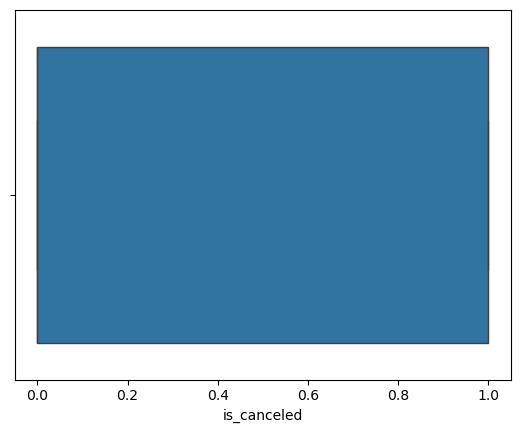

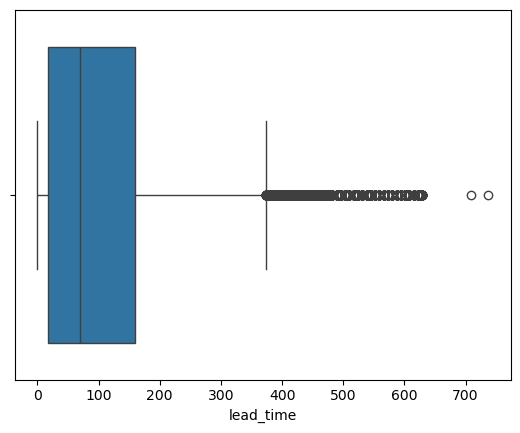

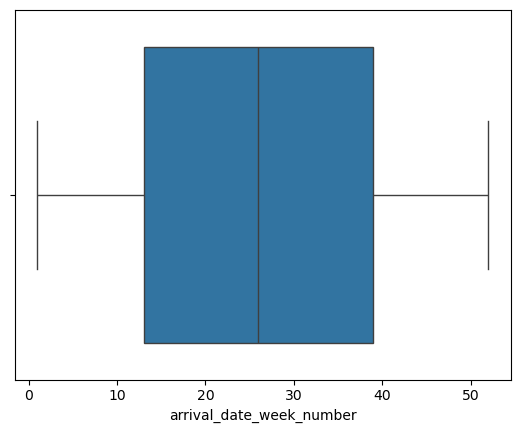

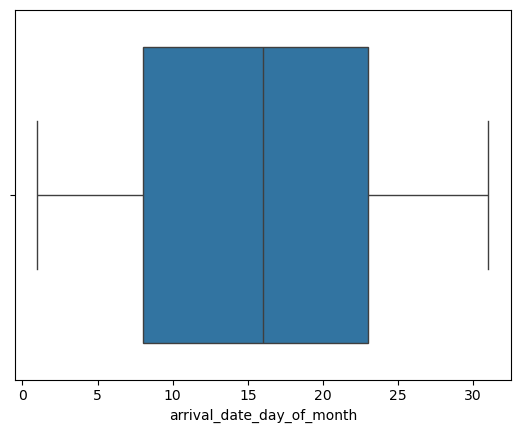

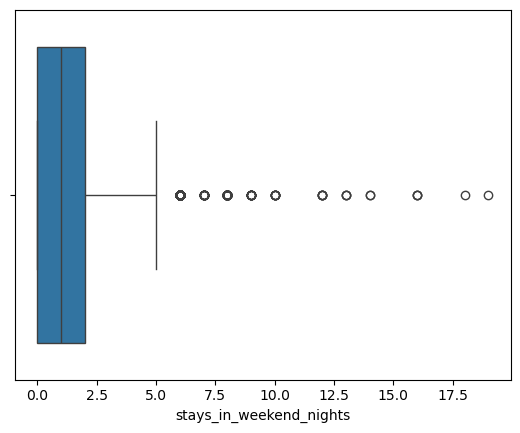

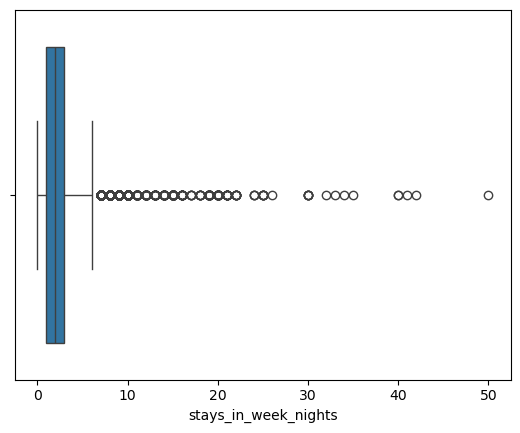

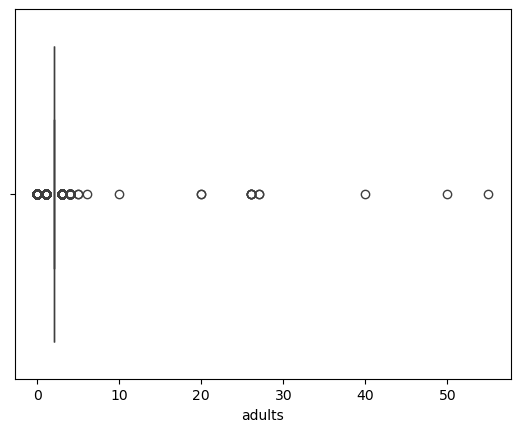

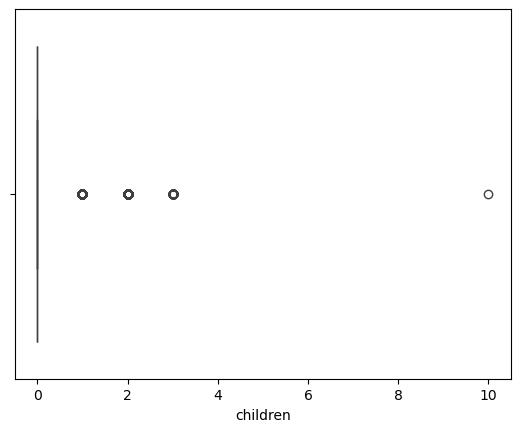

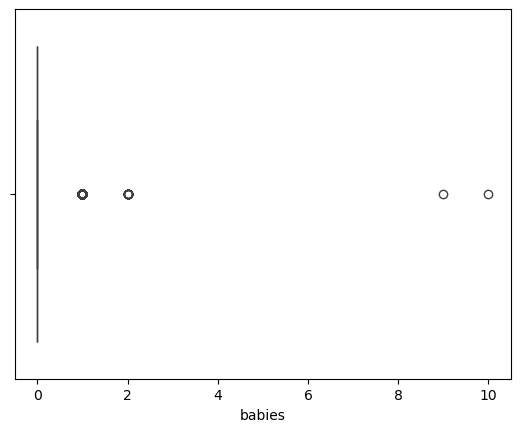

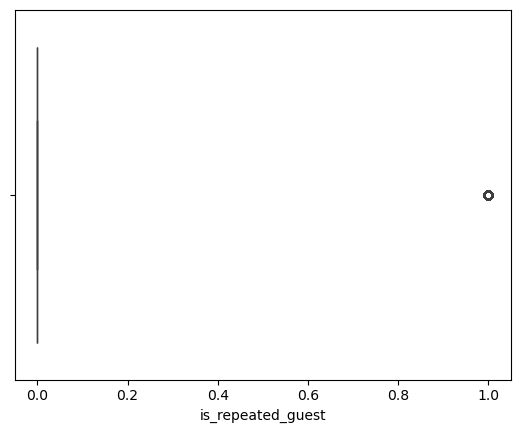

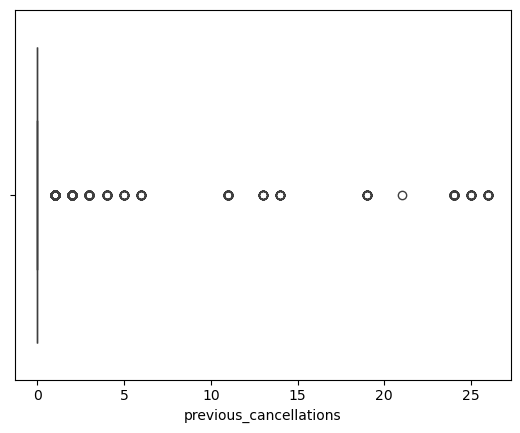

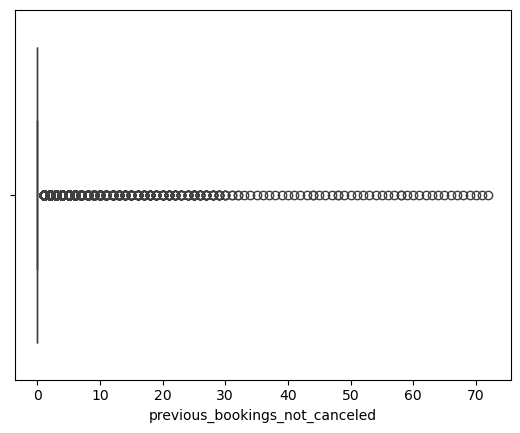

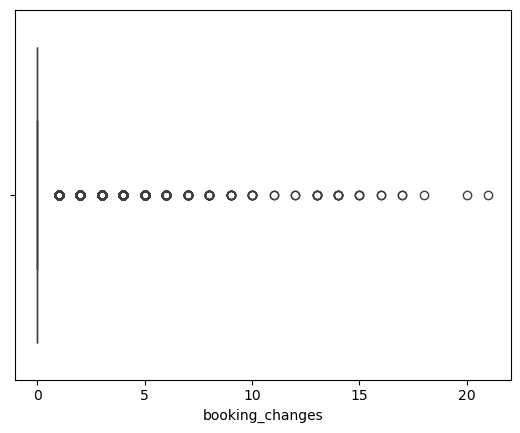

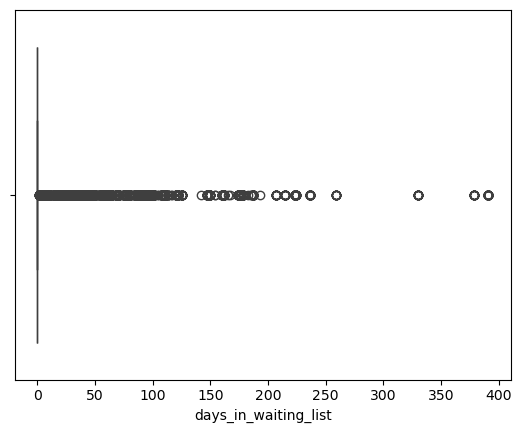

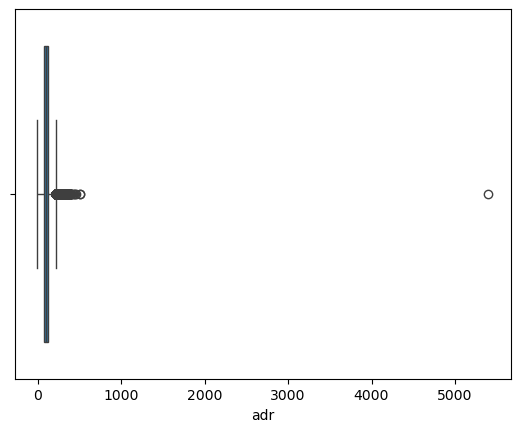

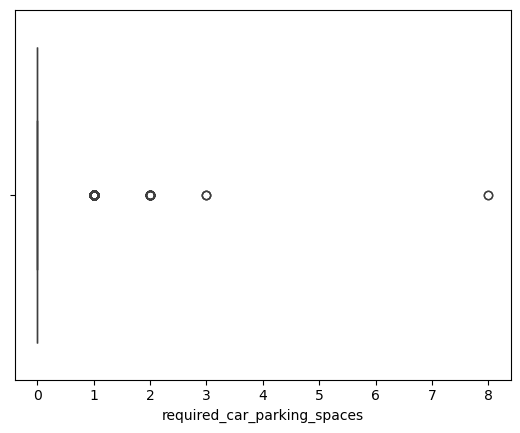

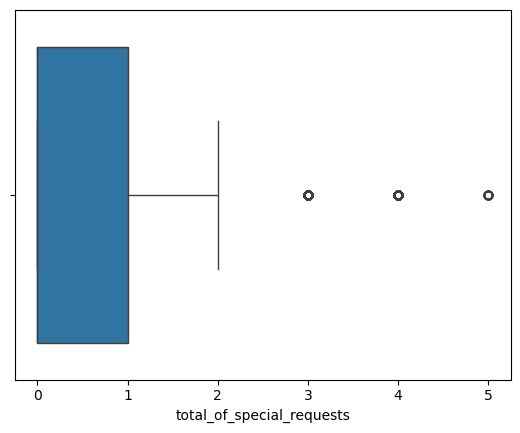

In [14]:
for i in df.select_dtypes(include= "number").columns:
    sns.boxplot(data=df,x=i)
    plt.show()

In [15]:
need_to_remove_outlairs=["lead_time", "adults", "stays_in_week_nights",
                         "days_in_waiting_list","booking_changes","adr","children"]
# df_2=pd.DataFrame()
for i in need_to_remove_outlairs:
    max_value = df[i].quantile(0.99)
    min_value=df[i].quantile(0.01)
    df[i] = df[i].clip(upper=max_value,lower=min_value)

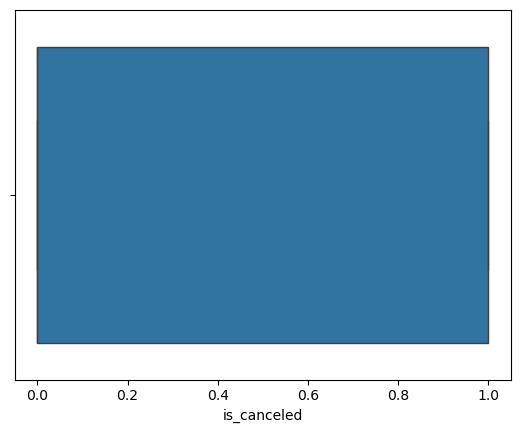

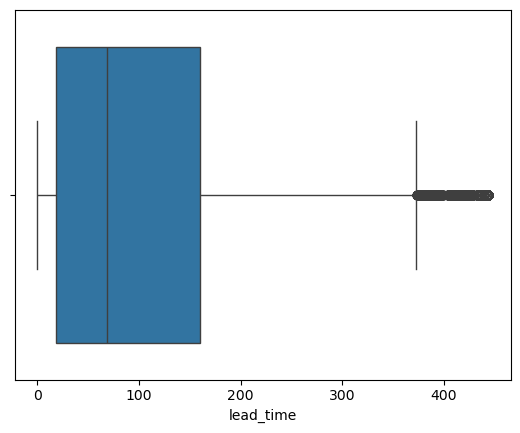

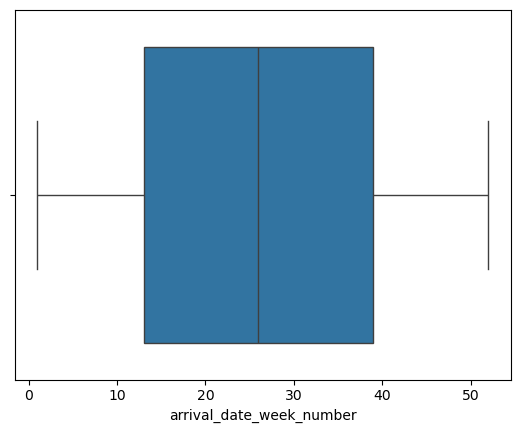

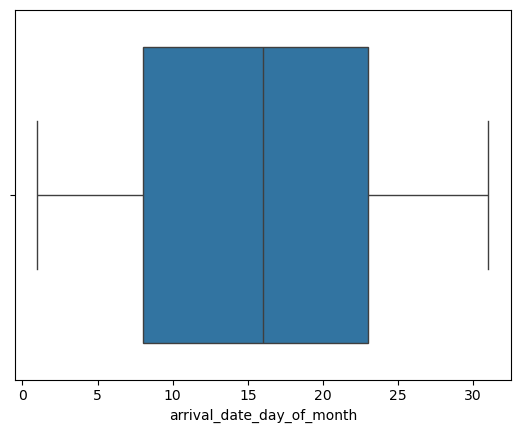

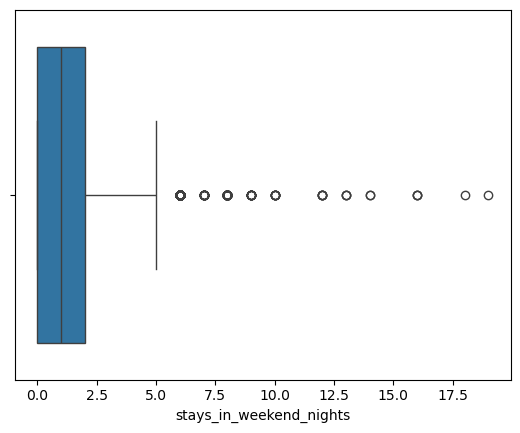

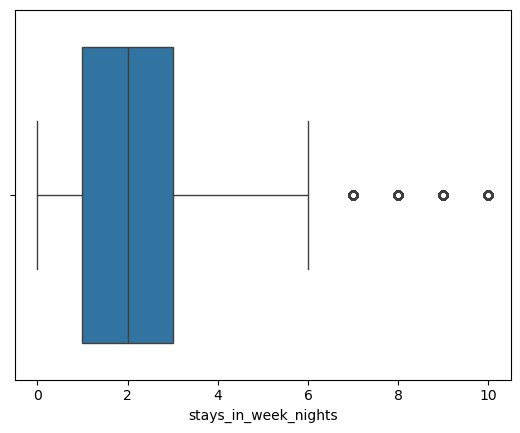

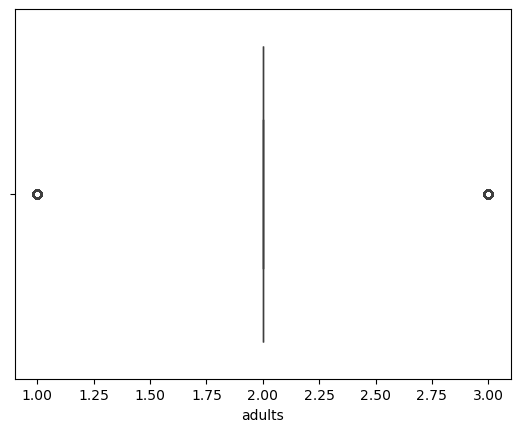

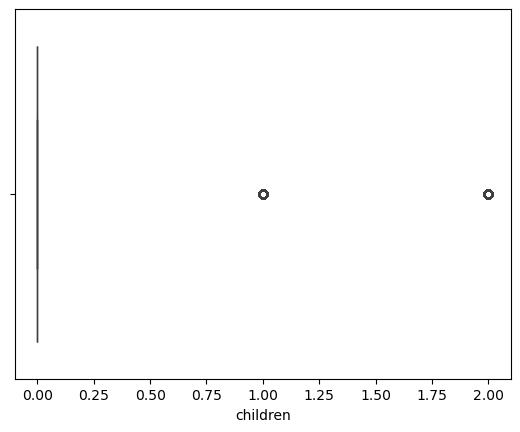

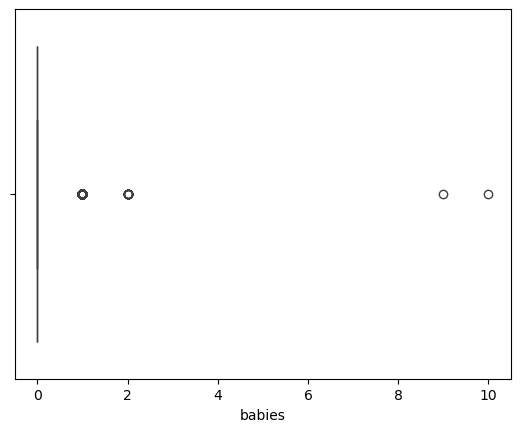

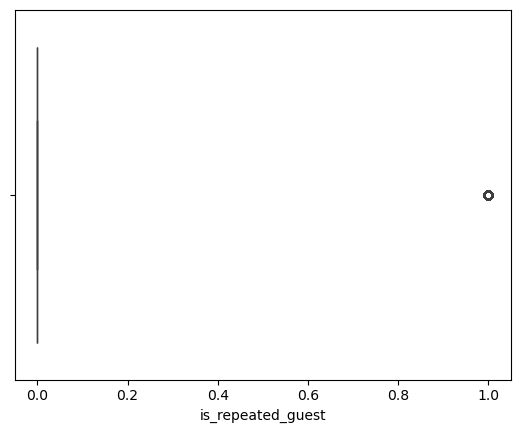

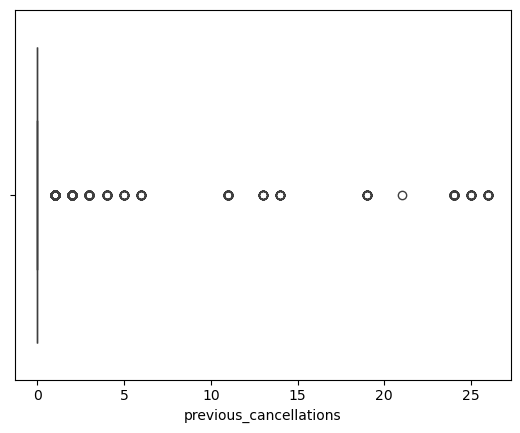

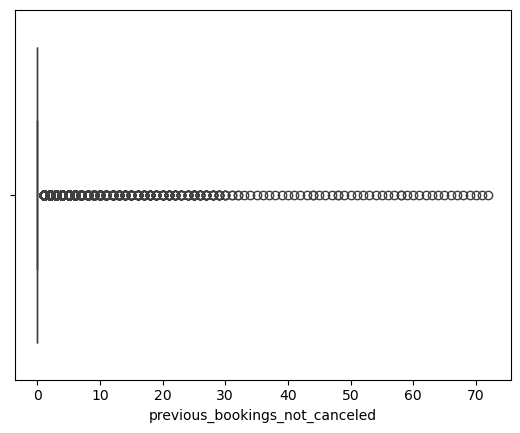

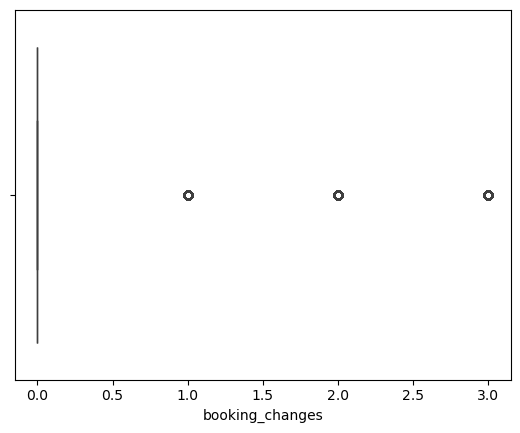

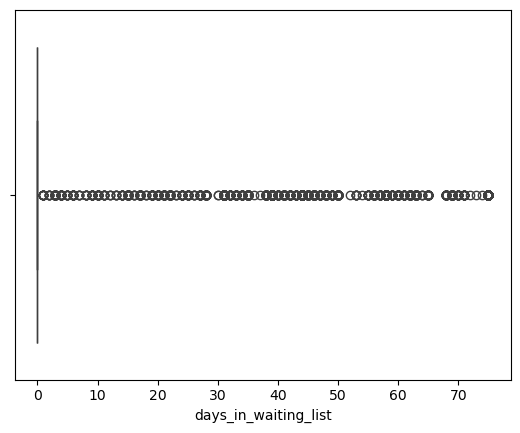

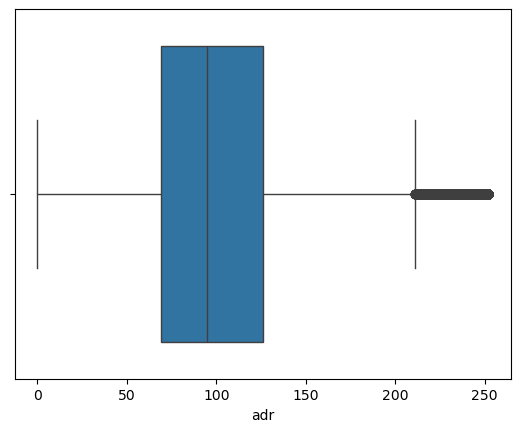

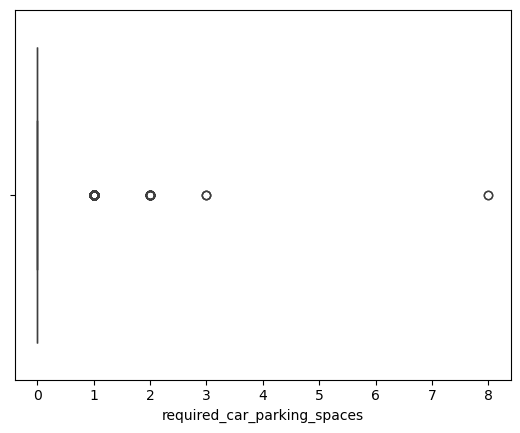

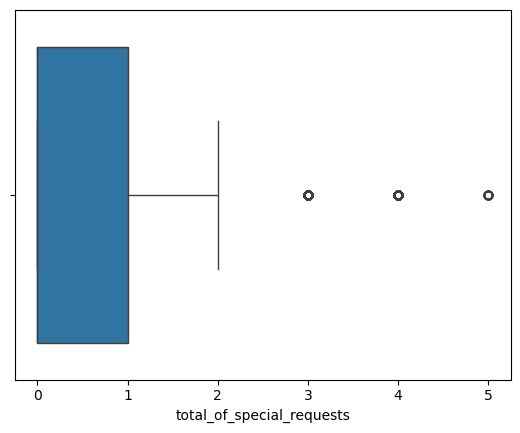

In [16]:
for i in df.select_dtypes(include= "number").columns:
    sns.boxplot(data=df,x=i)
    plt.show()

<Axes: >

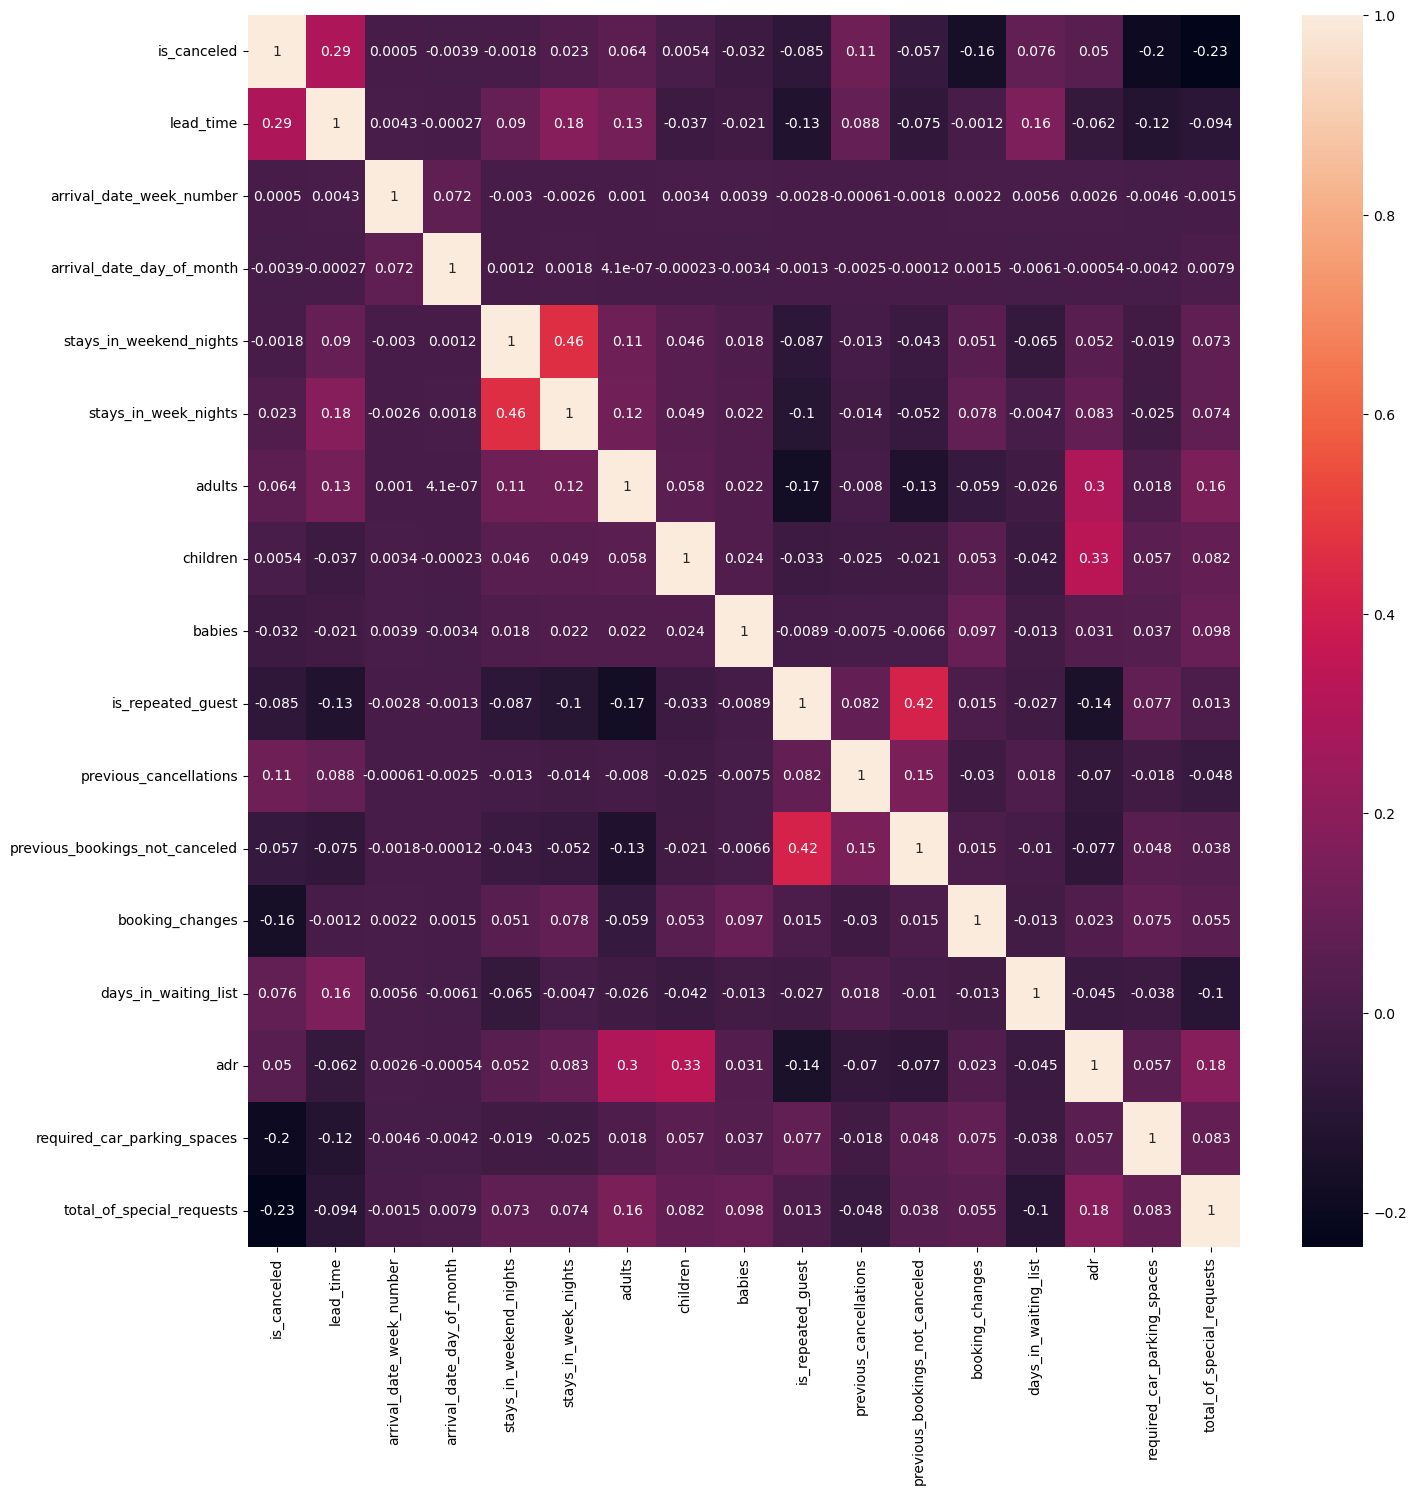

In [17]:
s = df.select_dtypes(include ="number").corr()
plt.figure(figsize=(16,16))
sns.heatmap(s,annot = True)

In [18]:
df.select_dtypes(include="object").columns
df.select_dtypes(include="object").shape
df.select_dtypes(include="object")

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,city
0,Resort Hotel - Chandigarh,July,BB,PRT,Direct,Direct,C,C,No Deposit,Transient,Chandigarh
1,Resort Hotel - Mumbai,April,BB,PRT,Direct,Direct,C,C,No Deposit,Transient,Mumbai
2,Resort Hotel - Delhi,September,BB,GBR,Direct,Direct,A,C,No Deposit,Transient,Delhi
3,Resort Hotel - Kolkata,August,BB,GBR,Corporate,Corporate,A,A,No Deposit,Transient,Kolkata
4,Resort Hotel - Lucknow,September,BB,GBR,Online TA,TA/TO,A,A,No Deposit,Transient,Lucknow
...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel - Pune,September,BB,BEL,Offline TA/TO,TA/TO,A,A,No Deposit,Transient,Pune
119386,City Hotel - Mumbai,November,BB,FRA,Online TA,TA/TO,E,E,No Deposit,Transient,Mumbai
119387,City Hotel - Lucknow,April,BB,DEU,Online TA,TA/TO,D,D,No Deposit,Transient,Lucknow
119388,City Hotel - Ahmedabad,October,BB,GBR,Online TA,TA/TO,A,A,No Deposit,Transient,Ahmedabad


In [19]:
df.select_dtypes(include="object").nunique()

hotel                    30
arrival_date_month       12
meal                      5
country                 177
market_segment            8
distribution_channel      5
reserved_room_type       10
assigned_room_type       12
deposit_type              3
customer_type             4
city                     15
dtype: int64

In [20]:
freq = df['hotel'].value_counts()
df['hotel_freq'] = df['hotel'].map(freq)

month_map = {
    "January": 1, "February": 2, "March": 3,
    "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9,
    "October": 10, "November": 11, "December": 12}
df["arrival_date_month_number"] = df["arrival_date_month"].map(month_map)


le = LabelEncoder()
for i in ["meal","market_segment","deposit_type","customer_type","distribution_channel"]:
    df[i+"_encoded"]=le.fit_transform(df[i])

df["got_reserved_room"]=(df["reserved_room_type"]==df["assigned_room_type"])
df["got_reserved_room_num"]=df["got_reserved_room"].map({False:0,True:1})


country_freq = df['country'].value_counts()
df['country_freq'] = df['country'].map(country_freq)


df = pd.get_dummies(df, columns=['city'])

df=df.drop(columns=["hotel","meal","arrival_date_month","got_reserved_room","reserved_room_type",
                    "assigned_room_type","country","market_segment","distribution_channel","deposit_type","customer_type"
                    ],axis=1)



In [21]:
df.head().T

,0,1,2,3,4
is_canceled,0,0,0,0,0
lead_time,342,444,7,13,14
arrival_date_week_number,30,17,37,33,37
arrival_date_day_of_month,27,28,10,14,14
stays_in_weekend_nights,0,0,0,0,0
stays_in_week_nights,0,0,1,1,2
adults,2,2,1,1,2
children,0.0,0.0,0.0,0.0,0.0
babies,0,0,0,0,0
is_repeated_guest,0,0,0,0,0


In [22]:
print(df.select_dtypes(include="object").nunique())
for i in df.select_dtypes(include="object").columns:
    print(df[i].value_counts() )

Series([], dtype: float64)


In [23]:
for i in df.columns[-15:]:
    df[i+"num"]=df[i].map({False:0,True:1})
    df=df.drop(columns=i)
df.head().T

,0,1,2,3,4
is_canceled,0.0,0.0,0.0,0.0,0.0
lead_time,342.0,444.0,7.0,13.0,14.0
arrival_date_week_number,30.0,17.0,37.0,33.0,37.0
arrival_date_day_of_month,27.0,28.0,10.0,14.0,14.0
stays_in_weekend_nights,0.0,0.0,0.0,0.0,0.0
stays_in_week_nights,0.0,0.0,1.0,1.0,2.0
adults,2.0,2.0,1.0,1.0,2.0
children,0.0,0.0,0.0,0.0,0.0
babies,0.0,0.0,0.0,0.0,0.0
is_repeated_guest,0.0,0.0,0.0,0.0,0.0


In [24]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

/tmp/ipykernel_8520/2409393893.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='is_canceled', palette=colors)


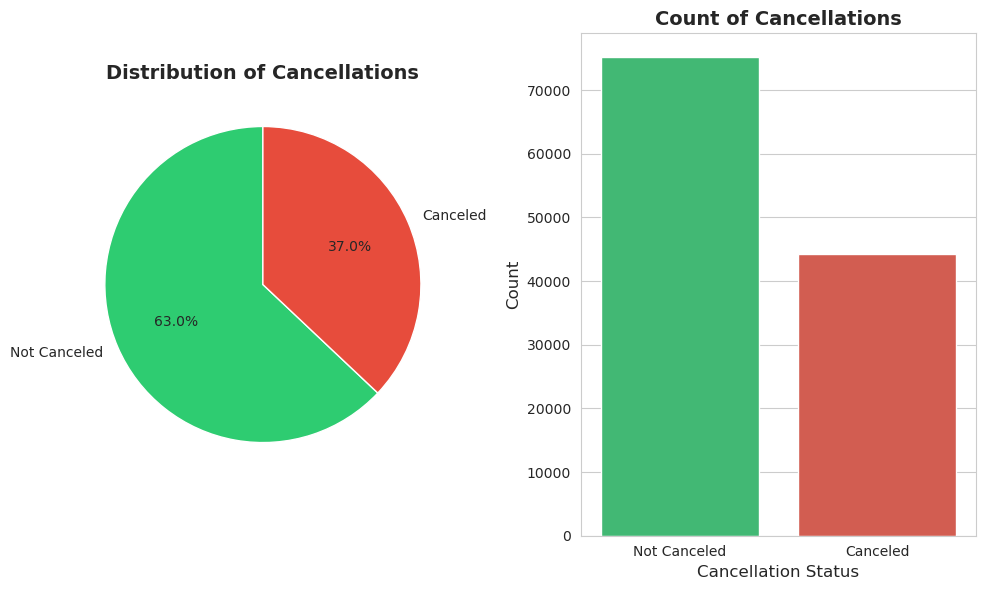

Aquired analysis:
Total Bookings: 119390
Canceled Bookings: 44224 (37.04%)
Not Canceled Bookings: 75166 (62.96%)


In [25]:
plt.figure(figsize=(10, 6))
cancellation_counts = df['is_canceled'].value_counts()
colors = ['#2ecc71', '#e74c3c']
plt.subplot(1, 2, 1)
plt.pie(cancellation_counts, labels=['Not Canceled', 'Canceled'],
        autopct='%1.1f%%', colors=colors, startangle=90)
plt.title('Distribution of Cancellations', fontsize=14, fontweight='bold')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='is_canceled', palette=colors)
plt.xlabel('Cancellation Status', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.title('Count of Cancellations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Aquired analysis:")

print(f"Total Bookings: {len(df)}")
print(f"Canceled Bookings: {cancellation_counts[1]} ({cancellation_counts[1]/len(df)*100:.2f}%)")
print(f"Not Canceled Bookings: {cancellation_counts[0]} ({cancellation_counts[0]/len(df)*100:.2f}%)")

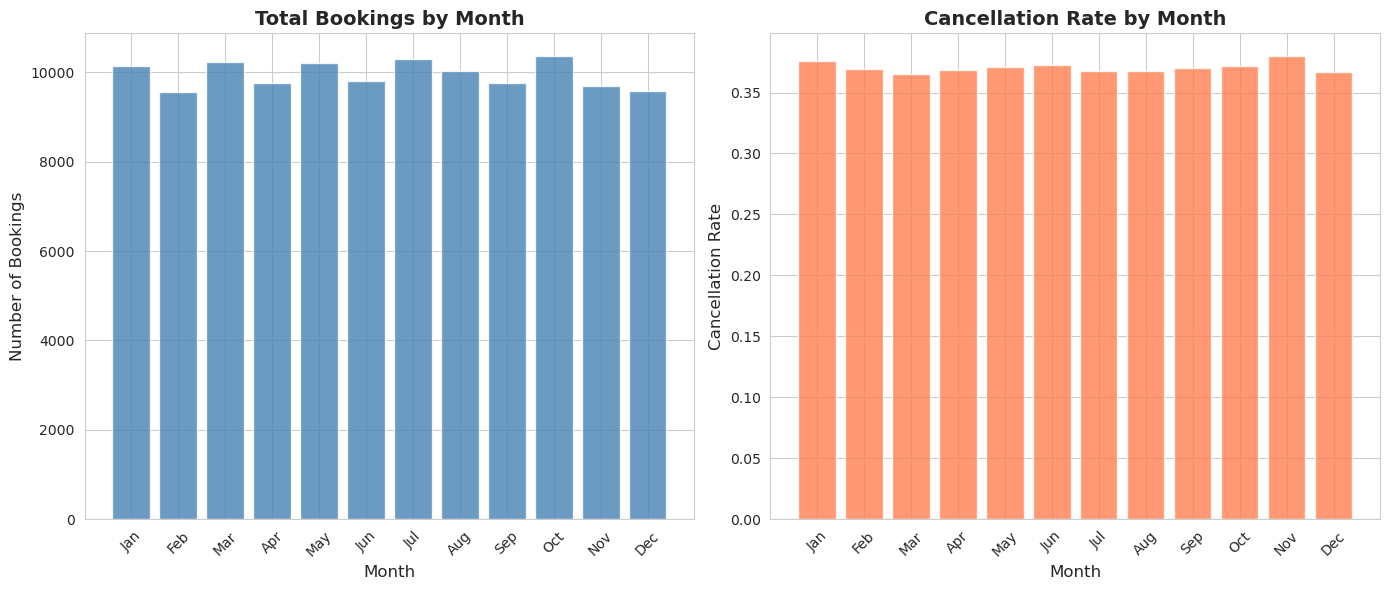

Aquired analysis:
Peak booking months: ['Oct', 'Jul', 'Mar']
Highest cancellation rate in: ['Nov', 'Jan', 'Jun']
Summer and holiday months show higher booking volumes but also higher cancellations.


In [26]:
plt.figure(figsize=(14, 6))

# Create month labels
month_labels = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
                7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}

# Bookings by month
plt.subplot(1, 2, 1)
month_counts = df['arrival_date_month_number'].value_counts().sort_index()
plt.bar(range(len(month_counts)), month_counts.values, color='steelblue', alpha=0.8)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.title('Total Bookings by Month', fontsize=14, fontweight='bold')
plt.xticks(range(len(month_counts)), [month_labels[i] for i in month_counts.index], rotation=45)

# Cancellations by month
plt.subplot(1, 2, 2)
month_cancel = df.groupby('arrival_date_month_number')['is_canceled'].mean().sort_index()
plt.bar(range(len(month_cancel)), month_cancel.values, color='coral', alpha=0.8)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Cancellation Rate', fontsize=12)
plt.title('Cancellation Rate by Month', fontsize=14, fontweight='bold')
plt.xticks(range(len(month_cancel)), [month_labels[i] for i in month_cancel.index], rotation=45)
plt.tight_layout()
plt.show()

peak_months = month_counts.nlargest(3).index.tolist()
high_cancel_months = month_cancel.nlargest(3).index.tolist()
print("Aquired analysis:")
print(f"Peak booking months: {[month_labels[m] for m in peak_months]}")
print(f"Highest cancellation rate in: {[month_labels[m] for m in high_cancel_months]}")
print("Summer and holiday months show higher booking volumes but also higher cancellations.")

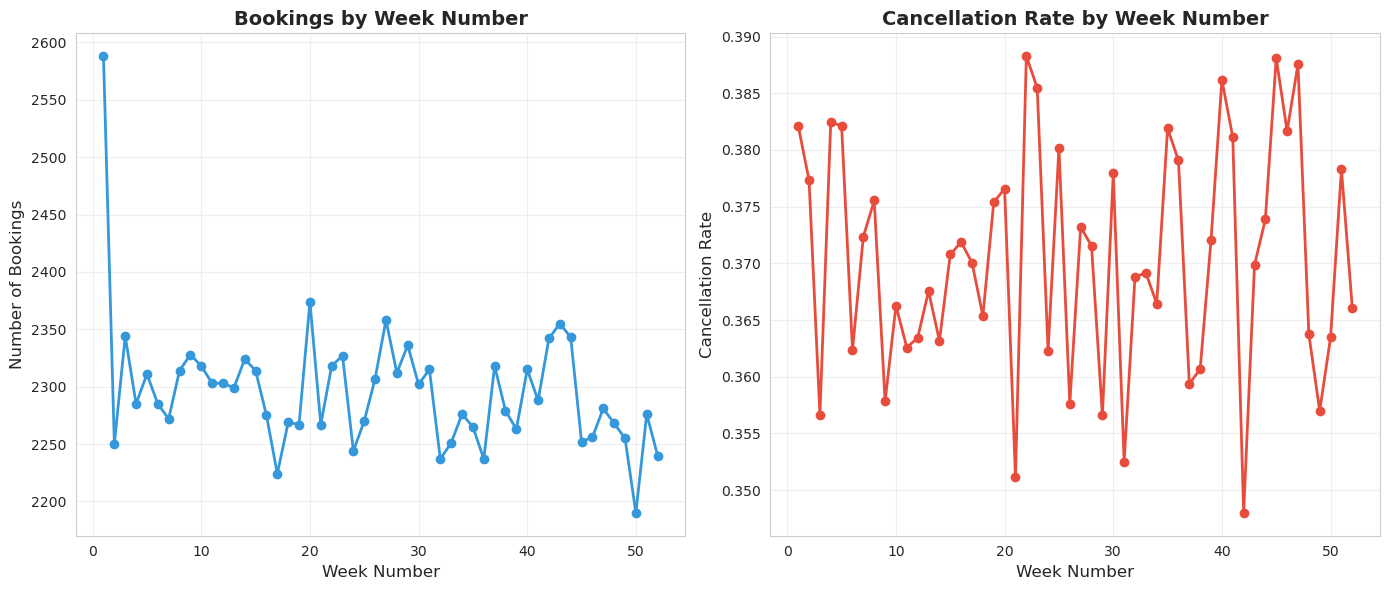

In [27]:
plt.figure(figsize=(14, 6))
week_data = df.groupby('arrival_date_week_number').agg({
    'is_canceled': ['count', 'mean']
}).reset_index()
week_data.columns = ['week', 'total_bookings', 'cancellation_rate']

plt.subplot(1, 2, 1)
plt.plot(week_data['week'], week_data['total_bookings'], marker='o', color='#3498db', linewidth=2)
plt.xlabel('Week Number', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.title('Bookings by Week Number', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(week_data['week'], week_data['cancellation_rate'], marker='o', color='#e74c3c', linewidth=2)
plt.xlabel('Week Number', fontsize=12)
plt.ylabel('Cancellation Rate', fontsize=12)
plt.title('Cancellation Rate by Week Number', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_8520/3546624904.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=city_counts.head(10).index, x=city_counts.head(10).values, palette='coolwarm')
/tmp/ipykernel_8520/3546624904.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=city_cancel.index, x=city_cancel.values, palette='RdYlGn_r')


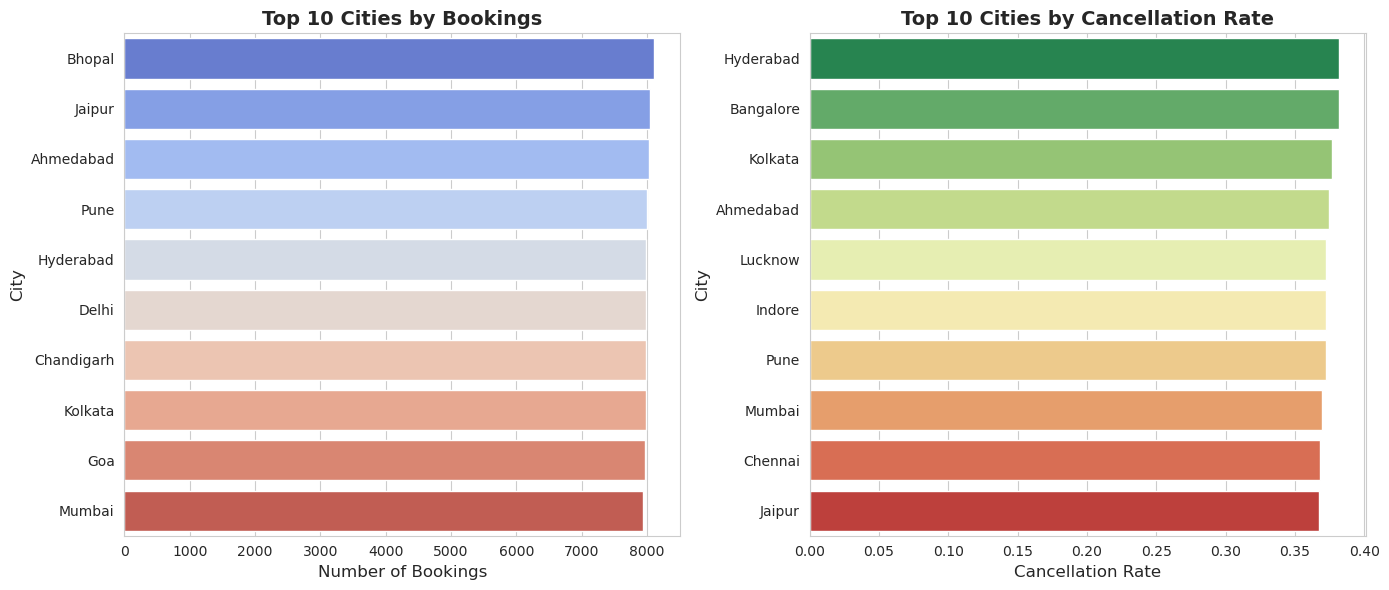

Aquired analysis:
Most popular cities: ['Bhopal', 'Jaipur', 'Ahmedabad']
Cities with highest cancellation rates: ['Hyderabad', 'Bangalore', 'Kolkata']


In [28]:
# Get all city columns
city_cols = [col for col in df.columns if col.startswith('city_') and col.endswith('num')]

# Reconstruct city data
city_bookings = {}
for col in city_cols:
    city_name = col.replace('city_', '').replace('num', '')
    city_bookings[city_name] = df[col].sum()

# Sort by bookings
city_counts = pd.Series(city_bookings).sort_values(ascending=False)

plt.figure(figsize=(14, 6))

# Bookings by city
plt.subplot(1, 2, 1)
sns.barplot(y=city_counts.head(10).index, x=city_counts.head(10).values, palette='coolwarm')
plt.xlabel('Number of Bookings', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.title('Top 10 Cities by Bookings', fontsize=14, fontweight='bold')

# Cancellation rate by city
plt.subplot(1, 2, 2)
city_cancel_rates = {}
for col in city_cols:
    city_name = col.replace('city_', '').replace('num', '')
    city_data = df[df[col] == 1]
    if len(city_data) > 0:
        city_cancel_rates[city_name] = city_data['is_canceled'].mean()

city_cancel = pd.Series(city_cancel_rates).sort_values(ascending=False).head(10)
sns.barplot(y=city_cancel.index, x=city_cancel.values, palette='RdYlGn_r')
plt.xlabel('Cancellation Rate', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.title('Top 10 Cities by Cancellation Rate', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Aquired analysis:")
print(f"Most popular cities: {city_counts.head(3).index.tolist()}")
print(f"Cities with highest cancellation rates: {city_cancel.head(3).index.tolist()}")


/tmp/ipykernel_8520/1818672722.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_canceled', y='adr', palette=['#2ecc71', '#e74c3c'])
/tmp/ipykernel_8520/1818672722.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='is_canceled', y='adr', palette=['#2ecc71', '#e74c3c'])


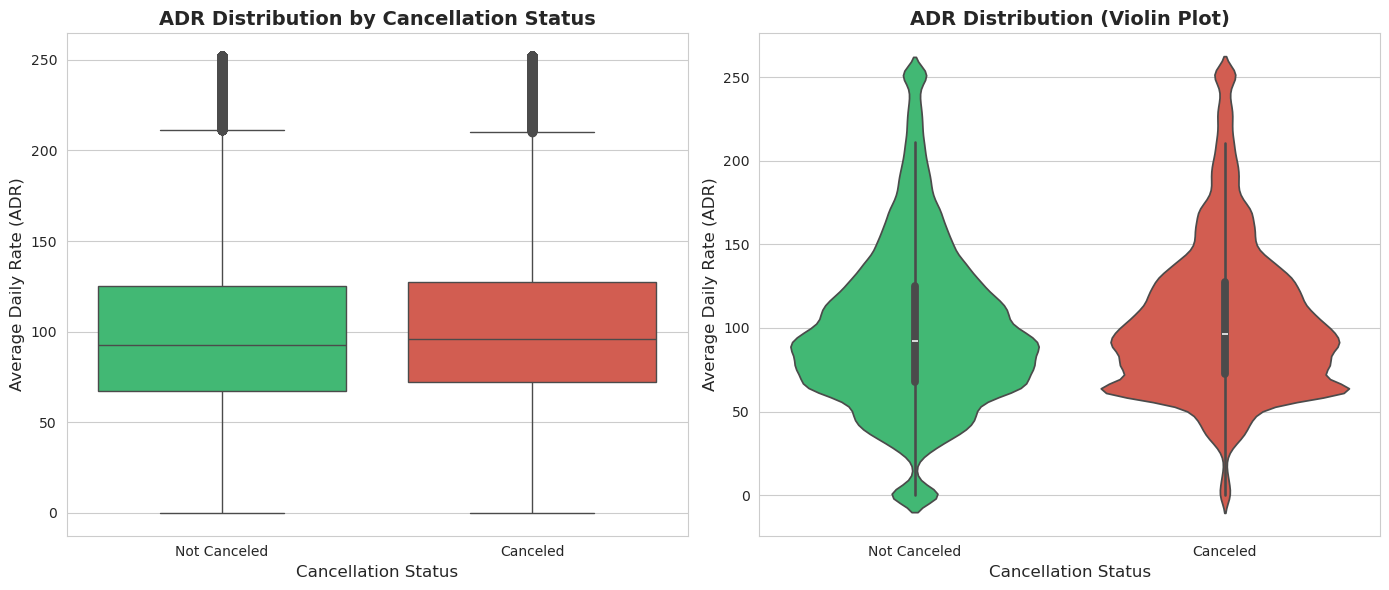


Mean ADR for Not Canceled: $99.65
Mean ADR for Canceled: $104.54
Aquired analysis:
Canceled bookings tend to have HIGHER average daily rates.
This suggests that price may be a factor in cancellation decisions.


In [29]:
plt.figure(figsize=(14, 6))

# Box plot
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='is_canceled', y='adr', palette=['#2ecc71', '#e74c3c'])
plt.xlabel('Cancellation Status', fontsize=12)
plt.ylabel('Average Daily Rate (ADR)', fontsize=12)
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.title('ADR Distribution by Cancellation Status', fontsize=14, fontweight='bold')

# Violin plot
plt.subplot(1, 2, 2)
sns.violinplot(data=df, x='is_canceled', y='adr', palette=['#2ecc71', '#e74c3c'])
plt.xlabel('Cancellation Status', fontsize=12)
plt.ylabel('Average Daily Rate (ADR)', fontsize=12)
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.title('ADR Distribution (Violin Plot)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nMean ADR for Not Canceled: ${df[df['is_canceled']==0]['adr'].mean():.2f}")
print(f"Mean ADR for Canceled: ${df[df['is_canceled']==1]['adr'].mean():.2f}")
print("Aquired analysis:")
if df[df['is_canceled']==1]['adr'].mean() > df[df['is_canceled']==0]['adr'].mean():
    print("Canceled bookings tend to have HIGHER average daily rates.")
    print("This suggests that price may be a factor in cancellation decisions.")
else:
    print("Canceled bookings tend to have LOWER average daily rates.")
    print("Lower-priced bookings might be more easily canceled by customers.")


/tmp/ipykernel_8520/2054446657.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_canceled', y='lead_time', palette=['#2ecc71', '#e74c3c'])


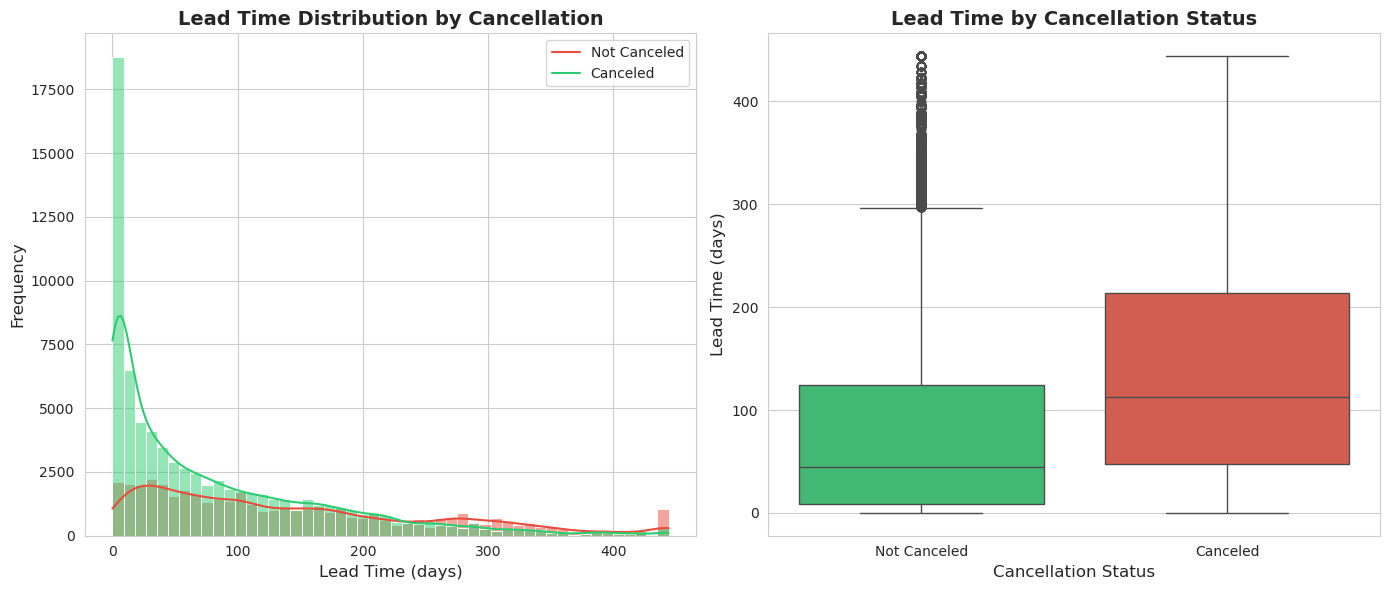


Mean Lead Time for Not Canceled: 79.86 days
Mean Lead Time for Canceled: 143.44 days
Aquired analysis:
Bookings with longer lead times (booked far in advance) have higher cancellation rates.
This makes sense as circumstances can change over longer periods.


In [30]:
plt.figure(figsize=(14, 6))

# Lead time distribution
plt.subplot(1, 2, 1)
sns.histplot(data=df, x='lead_time', hue='is_canceled', kde=True,
             palette=['#2ecc71', '#e74c3c'], bins=50)
plt.xlabel('Lead Time (days)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Lead Time Distribution by Cancellation', fontsize=14, fontweight='bold')
plt.legend(['Not Canceled', 'Canceled'])

# Box plot
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='is_canceled', y='lead_time', palette=['#2ecc71', '#e74c3c'])
plt.xlabel('Cancellation Status', fontsize=12)
plt.ylabel('Lead Time (days)', fontsize=12)
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.title('Lead Time by Cancellation Status', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nMean Lead Time for Not Canceled: {df[df['is_canceled']==0]['lead_time'].mean():.2f} days")
print(f"Mean Lead Time for Canceled: {df[df['is_canceled']==1]['lead_time'].mean():.2f} days")

print("Aquired analysis:")
print("Bookings with longer lead times (booked far in advance) have higher cancellation rates.")
print("This makes sense as circumstances can change over longer periods.")

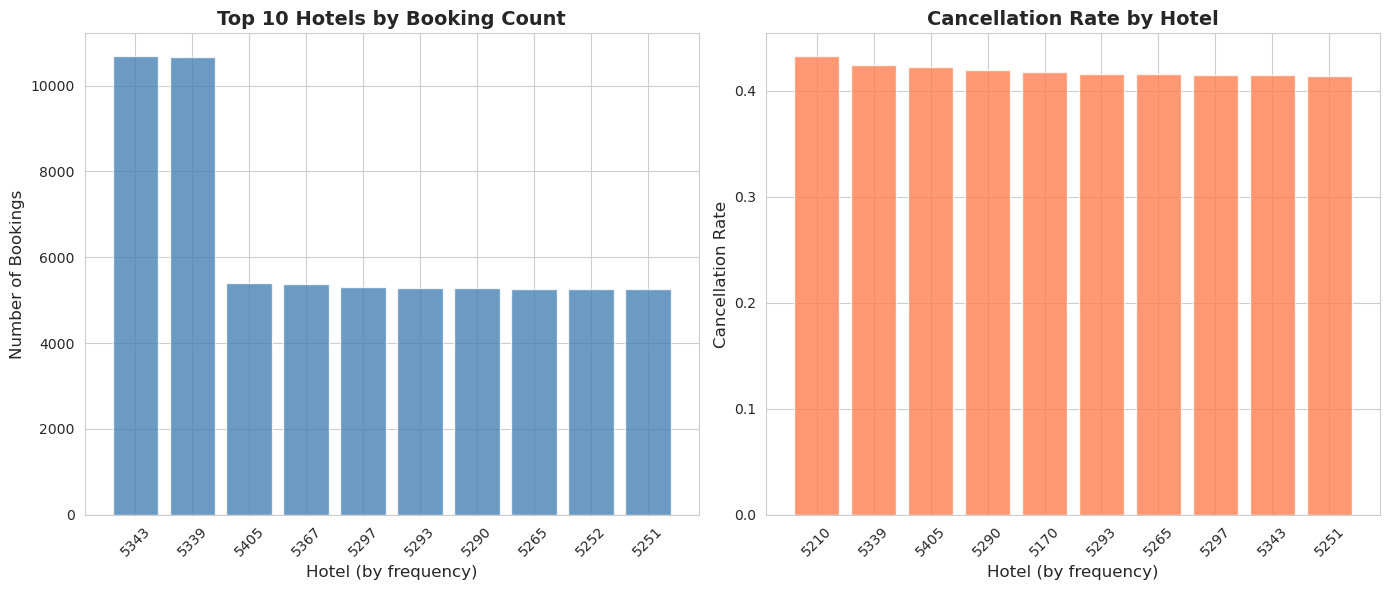

Aquired analysis:
Different hotels show varying booking volumes and cancellation patterns.
Hotels with higher booking frequencies may have different cancellation behaviors.


In [31]:
plt.figure(figsize=(14, 6))

# Hotel frequency distribution
plt.subplot(1, 2, 1)
hotel_freq_counts = df['hotel_freq'].value_counts().head(10)
plt.bar(range(len(hotel_freq_counts)), hotel_freq_counts.values, color='steelblue', alpha=0.8)
plt.xlabel('Hotel (by frequency)', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.title('Top 10 Hotels by Booking Count', fontsize=14, fontweight='bold')
plt.xticks(range(len(hotel_freq_counts)), hotel_freq_counts.index, rotation=45)

# Cancellation by hotel frequency
plt.subplot(1, 2, 2)
hotel_cancel = df.groupby('hotel_freq')['is_canceled'].mean().sort_values(ascending=False).head(10)
plt.bar(range(len(hotel_cancel)), hotel_cancel.values, color='coral', alpha=0.8)
plt.xlabel('Hotel (by frequency)', fontsize=12)
plt.ylabel('Cancellation Rate', fontsize=12)
plt.title('Cancellation Rate by Hotel', fontsize=14, fontweight='bold')
plt.xticks(range(len(hotel_cancel)), hotel_cancel.index, rotation=45)
plt.tight_layout()
plt.show()

print("Aquired analysis:")
print("Different hotels show varying booking volumes and cancellation patterns.")
print("Hotels with higher booking frequencies may have different cancellation behaviors.")

/tmp/ipykernel_8520/750364062.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segment_counts.index, y=segment_counts.values, palette='Set2')
/tmp/ipykernel_8520/750364062.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segment_cancel.index, y=segment_cancel.values, palette='RdYlGn_r')


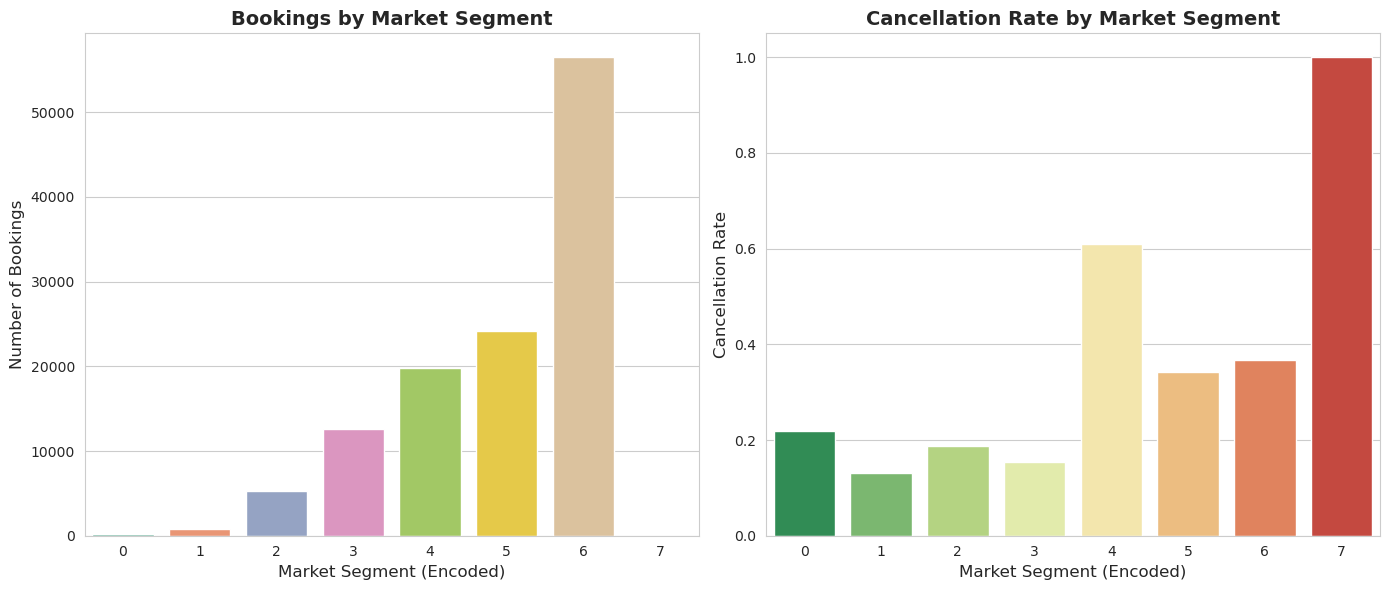


Cancellation Rate by Market Segment:
Segment 7: 100.00%
Segment 4: 61.06%
Segment 6: 36.72%
Segment 5: 34.32%
Segment 0: 21.94%
Segment 2: 18.73%
Segment 3: 15.34%
Segment 1: 13.06%
Aquired analysis:
Market segment significantly impacts cancellation behavior.
Different segments show varying cancellation patterns that can help prediction.


In [32]:
plt.figure(figsize=(14, 6))

# Bookings by market segment
plt.subplot(1, 2, 1)
segment_counts = df['market_segment_encoded'].value_counts()
sns.barplot(x=segment_counts.index, y=segment_counts.values, palette='Set2')
plt.xlabel('Market Segment (Encoded)', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.title('Bookings by Market Segment', fontsize=14, fontweight='bold')

# Cancellation rate by market segment
plt.subplot(1, 2, 2)
segment_cancel = df.groupby('market_segment_encoded')['is_canceled'].mean().sort_values(ascending=False)
sns.barplot(x=segment_cancel.index, y=segment_cancel.values, palette='RdYlGn_r')
plt.xlabel('Market Segment (Encoded)', fontsize=12)
plt.ylabel('Cancellation Rate', fontsize=12)
plt.title('Cancellation Rate by Market Segment', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nCancellation Rate by Market Segment:")
for segment, rate in segment_cancel.items():
    print(f"Segment {segment}: {rate*100:.2f}%")

print("Aquired analysis:")
print("Market segment significantly impacts cancellation behavior.")
print("Different segments show varying cancellation patterns that can help prediction.")


/tmp/ipykernel_8520/1514679718.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=customer_counts.index, y=customer_counts.values, palette='husl')
/tmp/ipykernel_8520/1514679718.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=customer_cancel.index, y=customer_cancel.values, palette='RdYlGn_r')


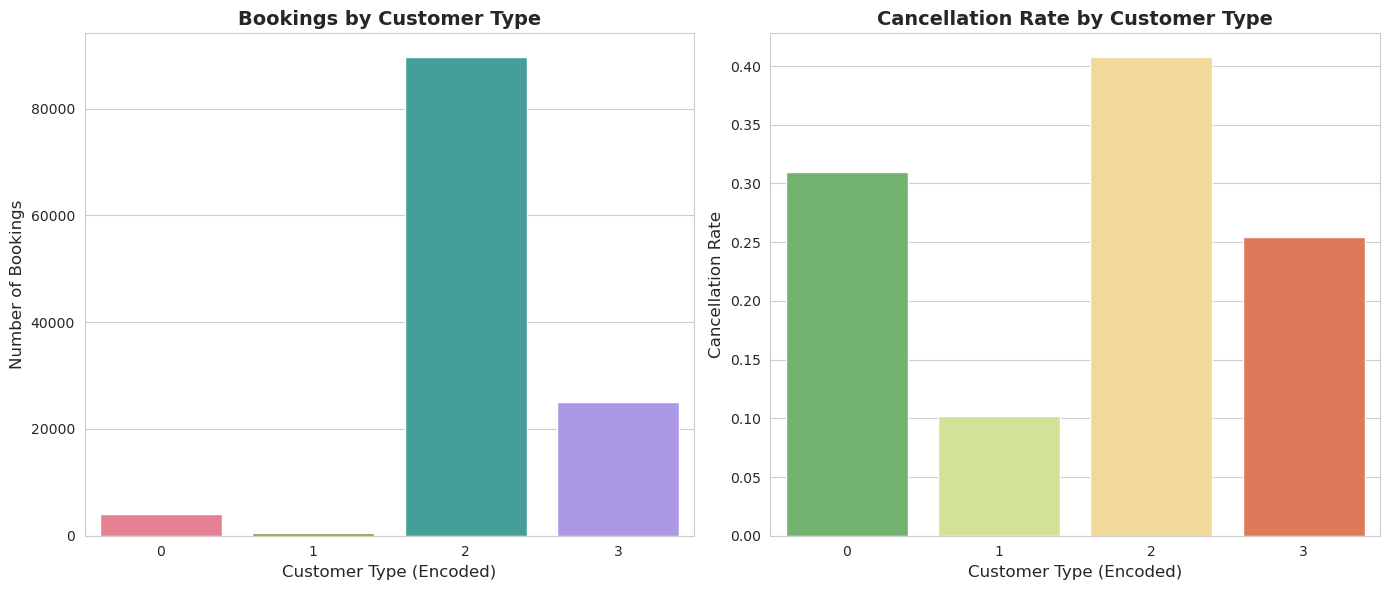


Cancellation Rate by Customer Type:
Customer Type 2: 40.75%
Customer Type 0: 30.96%
Customer Type 3: 25.43%
Customer Type 1: 10.23%
Aquired analysis:
Different customer types show distinct cancellation patterns.
This encoded feature will be valuable for the prediction model.


In [33]:
plt.figure(figsize=(14, 6))

# Bookings by customer type
plt.subplot(1, 2, 1)
customer_counts = df['customer_type_encoded'].value_counts()
sns.barplot(x=customer_counts.index, y=customer_counts.values, palette='husl')
plt.xlabel('Customer Type (Encoded)', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.title('Bookings by Customer Type', fontsize=14, fontweight='bold')

# Cancellation rate by customer type
plt.subplot(1, 2, 2)
customer_cancel = df.groupby('customer_type_encoded')['is_canceled'].mean().sort_values(ascending=False)
sns.barplot(x=customer_cancel.index, y=customer_cancel.values, palette='RdYlGn_r')
plt.xlabel('Customer Type (Encoded)', fontsize=12)
plt.ylabel('Cancellation Rate', fontsize=12)
plt.title('Cancellation Rate by Customer Type', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nCancellation Rate by Customer Type:")
for ctype, rate in customer_cancel.items():
    print(f"Customer Type {ctype}: {rate*100:.2f}%")

print("Aquired analysis:")
print("Different customer types show distinct cancellation patterns.")
print("This encoded feature will be valuable for the prediction model.")


<Figure size 1200x600 with 0 Axes>

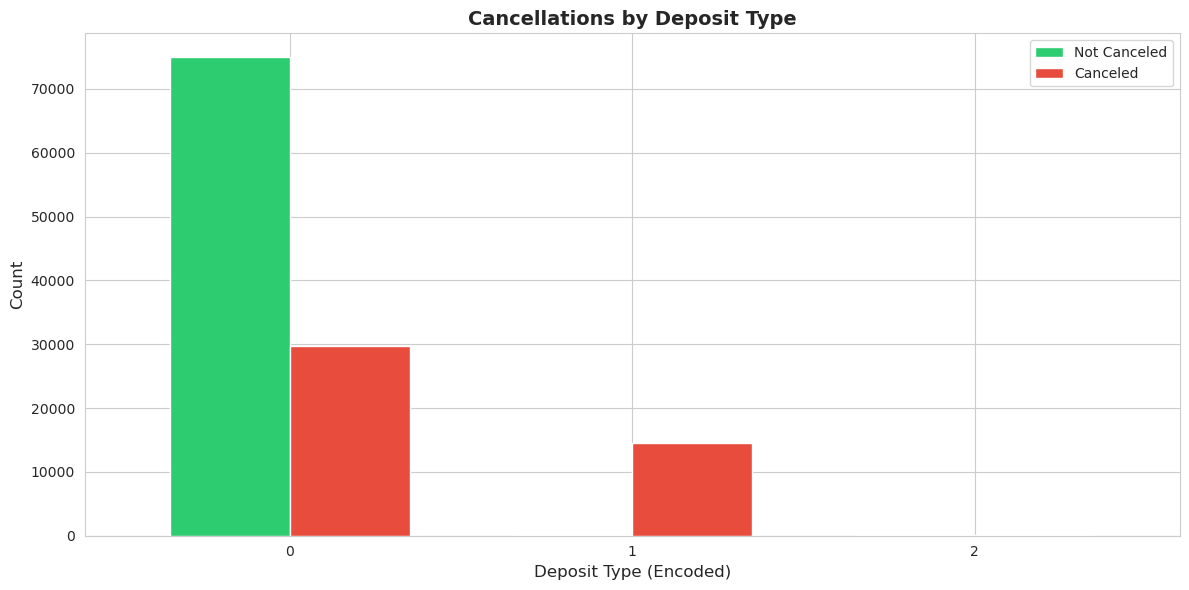


Cancellation Rate by Deposit Type:
Deposit Type 1: 99.36%
Deposit Type 0: 28.38%
Deposit Type 2: 22.22%
Aquired analysis:
Deposit type is a VERY strong indicator of cancellation likelihood.
Different deposit types show dramatically different cancellation rates.


In [34]:
plt.figure(figsize=(12, 6))
deposit_cancel = df.groupby(['deposit_type_encoded', 'is_canceled']).size().unstack()
deposit_cancel.plot(kind='bar', color=['#2ecc71', '#e74c3c'], width=0.7)
plt.xlabel('Deposit Type (Encoded)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.title('Cancellations by Deposit Type', fontsize=14, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(['Not Canceled', 'Canceled'])
plt.tight_layout()
plt.show()

deposit_cancel_rate = df.groupby('deposit_type_encoded')['is_canceled'].mean().sort_values(ascending=False)
print("\nCancellation Rate by Deposit Type:")
for dtype, rate in deposit_cancel_rate.items():
    print(f"Deposit Type {dtype}: {rate*100:.2f}%")

print("Aquired analysis:")
print("Deposit type is a VERY strong indicator of cancellation likelihood.")
print("Different deposit types show dramatically different cancellation rates.")


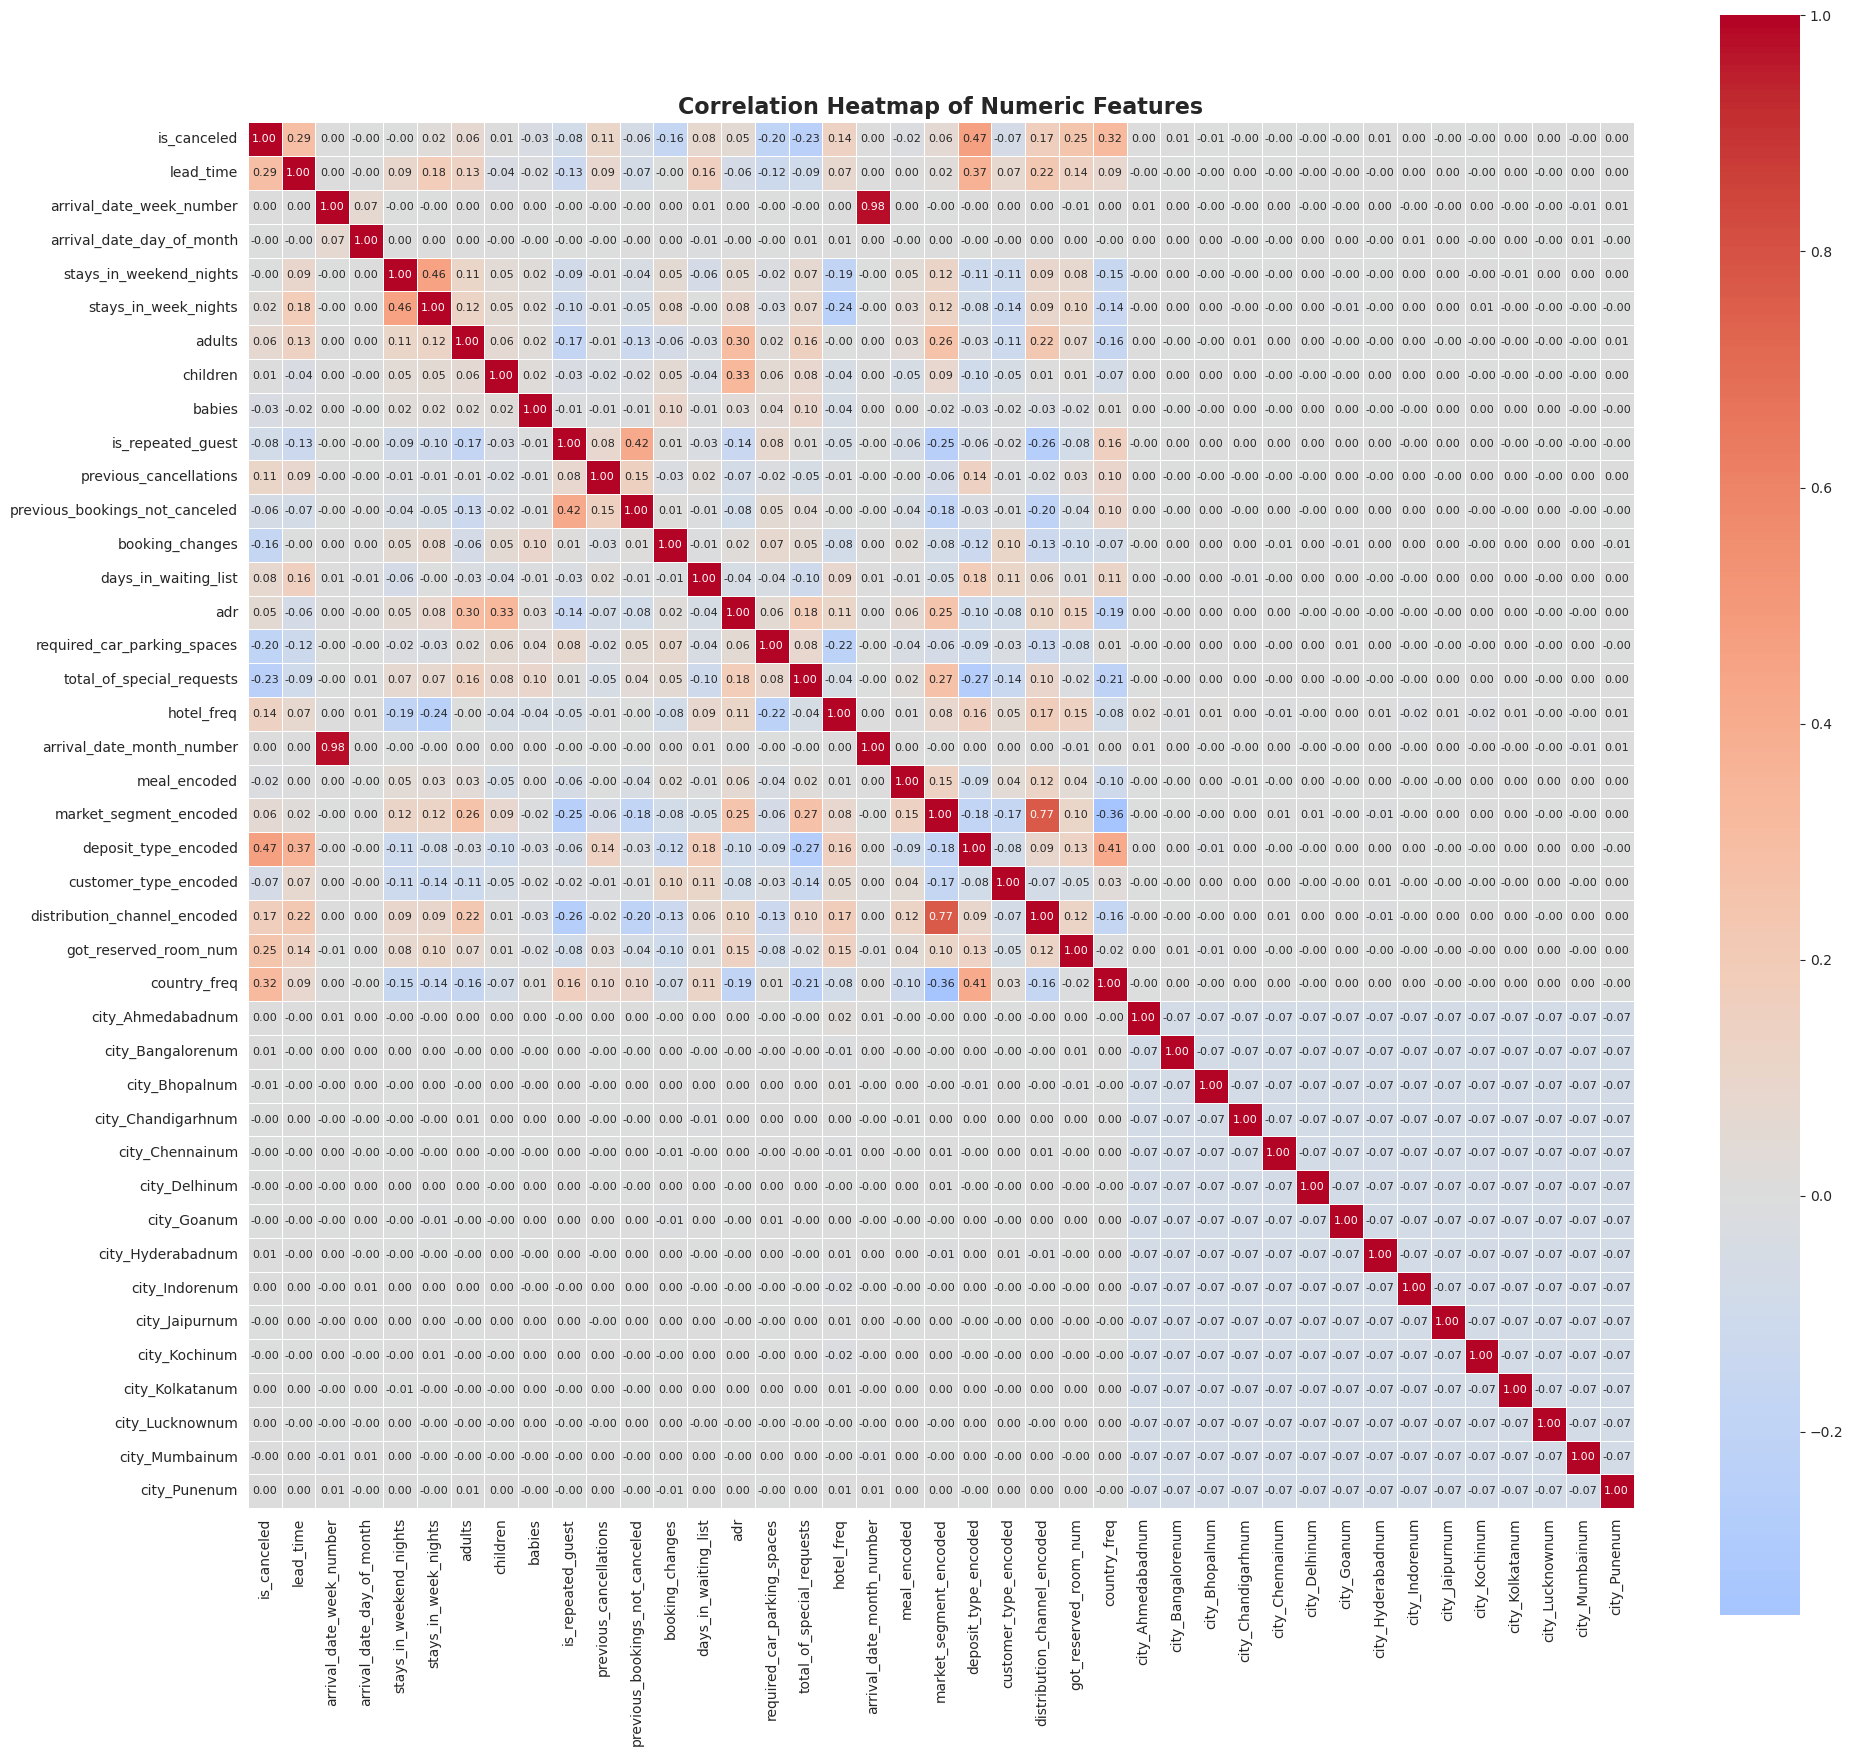


Top Positive Correlations with Cancellation:
deposit_type_encoded            0.468634
country_freq                    0.318797
lead_time                       0.293567
got_reserved_room_num           0.247770
distribution_channel_encoded    0.167600
Name: is_canceled, dtype: float64

Top Negative Correlations with Cancellation:
customer_type_encoded         -0.068140
is_repeated_guest             -0.084793
booking_changes               -0.160848
required_car_parking_spaces   -0.195498
total_of_special_requests     -0.234658
Name: is_canceled, dtype: float64
Aquired analysis:
Features most correlated with cancellations can be prioritized in modeling.
Lead time, deposit type, and previous cancellations show strong relationships.


In [35]:
# Select numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', square=True, linewidths=0.5, annot_kws={'size': 8})
plt.title('Correlation Heatmap of Numeric Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Top correlations with is_canceled
cancel_corr = correlation_matrix['is_canceled'].sort_values(ascending=False)
print("\nTop Positive Correlations with Cancellation:")
print(cancel_corr[1:6])
print("\nTop Negative Correlations with Cancellation:")
print(cancel_corr[-5:])

print("Aquired analysis:")
print("Features most correlated with cancellations can be prioritized in modeling.")
print("Lead time, deposit type, and previous cancellations show strong relationships.")

/tmp/ipykernel_8520/3764471885.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_canceled', y='total_of_special_requests',


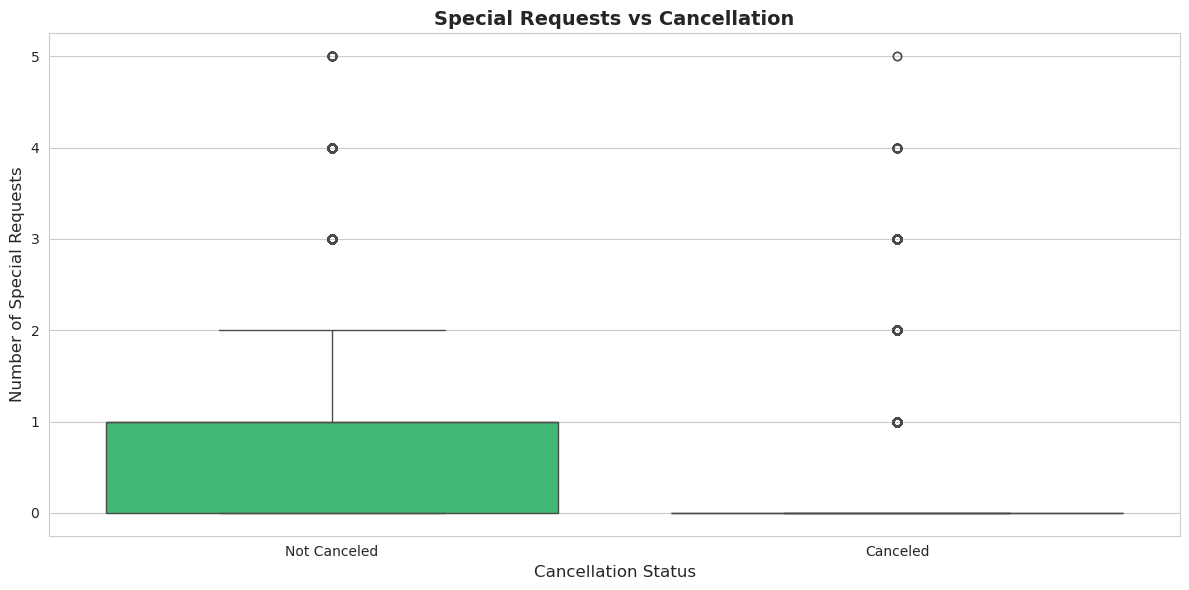


Mean Special Requests for Not Canceled: 0.71
Mean Special Requests for Canceled: 0.33
Aquired analysis:
Bookings with more special requests tend to have lower cancellation rates.
This indicates customer commitment and engagement with the booking.


In [36]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='is_canceled', y='total_of_special_requests',
            palette=['#2ecc71', '#e74c3c'])
plt.xlabel('Cancellation Status', fontsize=12)
plt.ylabel('Number of Special Requests', fontsize=12)
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.title('Special Requests vs Cancellation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nMean Special Requests for Not Canceled: {df[df['is_canceled']==0]['total_of_special_requests'].mean():.2f}")
print(f"Mean Special Requests for Canceled: {df[df['is_canceled']==1]['total_of_special_requests'].mean():.2f}")

print("Aquired analysis:")
print("Bookings with more special requests tend to have lower cancellation rates.")
print("This indicates customer commitment and engagement with the booking.")


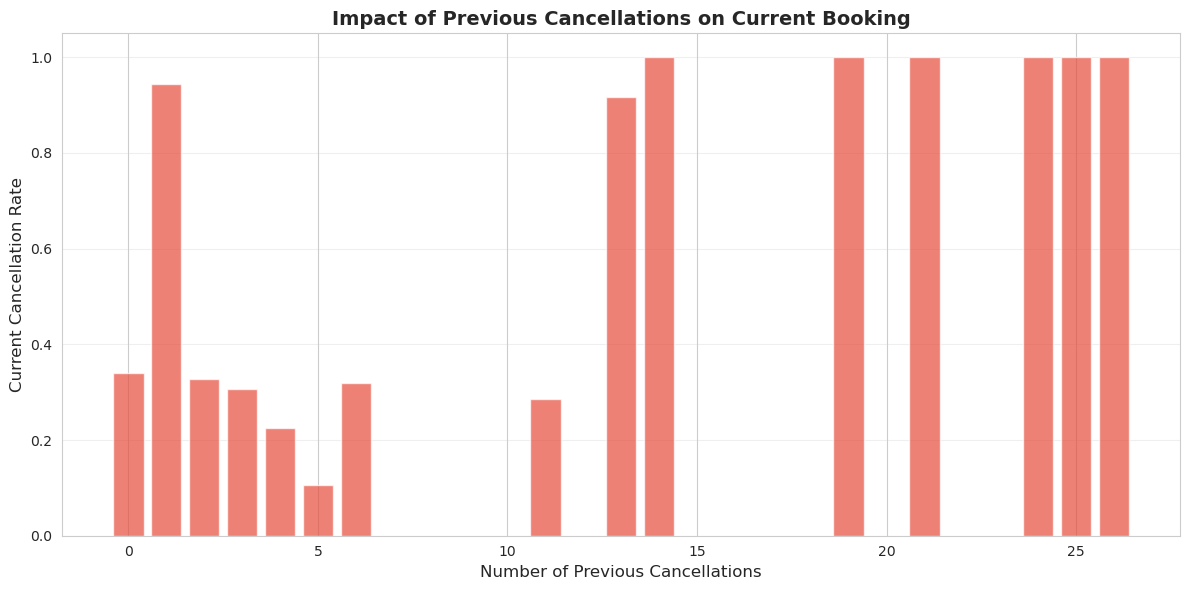

Aquired analysis:
Customers with history of cancellations are MORE likely to cancel again.
This is a strong predictor and should be weighted heavily in the model.


In [37]:
plt.figure(figsize=(12, 6))
prev_cancel_rate = df.groupby('previous_cancellations')['is_canceled'].mean()
plt.bar(prev_cancel_rate.index, prev_cancel_rate.values, color='#e74c3c', alpha=0.7)
plt.xlabel('Number of Previous Cancellations', fontsize=12)
plt.ylabel('Current Cancellation Rate', fontsize=12)
plt.title('Impact of Previous Cancellations on Current Booking', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("Aquired analysis:")

print("Customers with history of cancellations are MORE likely to cancel again.")
print("This is a strong predictor and should be weighted heavily in the model.")


/tmp/ipykernel_8520/2190640396.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_canceled', y='total_stay', palette=['#2ecc71', '#e74c3c'])


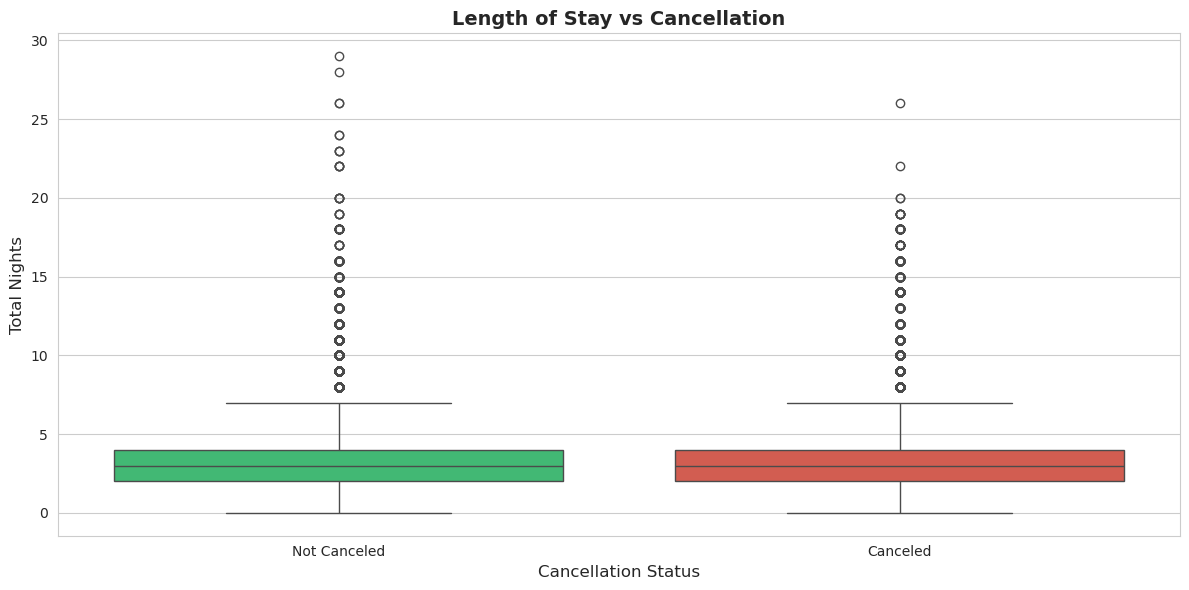


Mean Total Stay for Not Canceled: 3.38 nights
Mean Total Stay for Canceled: 3.46 nights
Aquired analysis:
Longer stays tend to have higher cancellation rates.


In [38]:
# Create total stay column if not exists
if 'total_stay' not in df.columns:
    df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='is_canceled', y='total_stay', palette=['#2ecc71', '#e74c3c'])
plt.xlabel('Cancellation Status', fontsize=12)
plt.ylabel('Total Nights', fontsize=12)
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.title('Length of Stay vs Cancellation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nMean Total Stay for Not Canceled: {df[df['is_canceled']==0]['total_stay'].mean():.2f} nights")
print(f"Mean Total Stay for Canceled: {df[df['is_canceled']==1]['total_stay'].mean():.2f} nights")

print("Aquired analysis:")
print("Longer stays tend to have higher cancellation rates.")

In [39]:
#imports:

# ___________________________________________________________________________________________________________________________________________________

# part D: new features:

df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

df['total_guests'] = df['adults'] + df['children'] + df['babies']

df['is_family'] = ((df['children'] + df['babies']) > 0).astype(int)

# df['cancel_ratio'] = df['previous_cancellations'] / (df['previous_total_bookings'] + 1)

df['adr_level'] = pd.qcut(df['adr'], q=3, labels=[0, 1, 2]).astype(int)

# df['has_agent'] = df['agent'].notna().astype(int)
# df['has_company'] = df['company'].notna().astype(int)

# df.drop(['agent', 'company'], axis=1, inplace=True)


In [40]:
#---------------------------------------------------------------------------------------------------------------------------------------------
#dataset splitting:
X = df.drop('is_canceled', axis=1)
y = df['is_canceled']

# first split: split data into temp and test
X_train_temp, X_test, y_train_temp, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

# second split: split temp into train and validation
# 0.25 of 0.8 is 0.2 of all data
X_train, X_val, y_train, y_val = train_test_split(
    X_train_temp, y_train_temp, test_size=0.25, random_state=42, stratify=y_train_temp
)
print(f"Dataset Split Sizes:")
print(f"Training: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Dataset Split Sizes:
Training: 71634 | Validation: 23878 | Test: 23878


In [41]:
print(X_train.isnull().sum())

lead_time                         0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
booking_changes                   0
days_in_waiting_list              0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
hotel_freq                        0
arrival_date_month_number         0
meal_encoded                      0
market_segment_encoded            0
deposit_type_encoded              0
customer_type_encoded             0
distribution_channel_encoded      0
got_reserved_room_num             0
country_freq                      0
city_Ahmedabadnum                 0
city_Bangalorenum                 0
city_Bhopalnum              

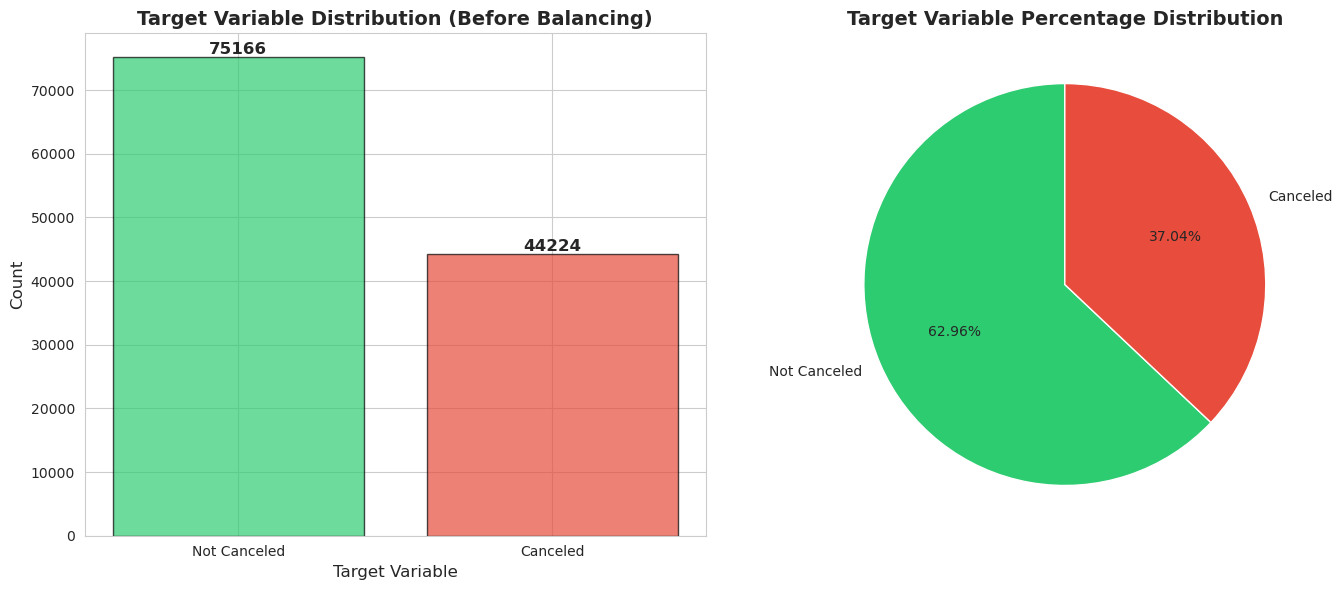


Class Distribution:
Not Canceled (0): 75166 (62.96%)
Canceled (1): 44224 (37.04%)

Imbalance Ratio: 1.70:1

⚠️ DATASET IS IMBALANCED!
Applying SMOTE (Synthetic Minority Over-sampling Technique) to Training Data...


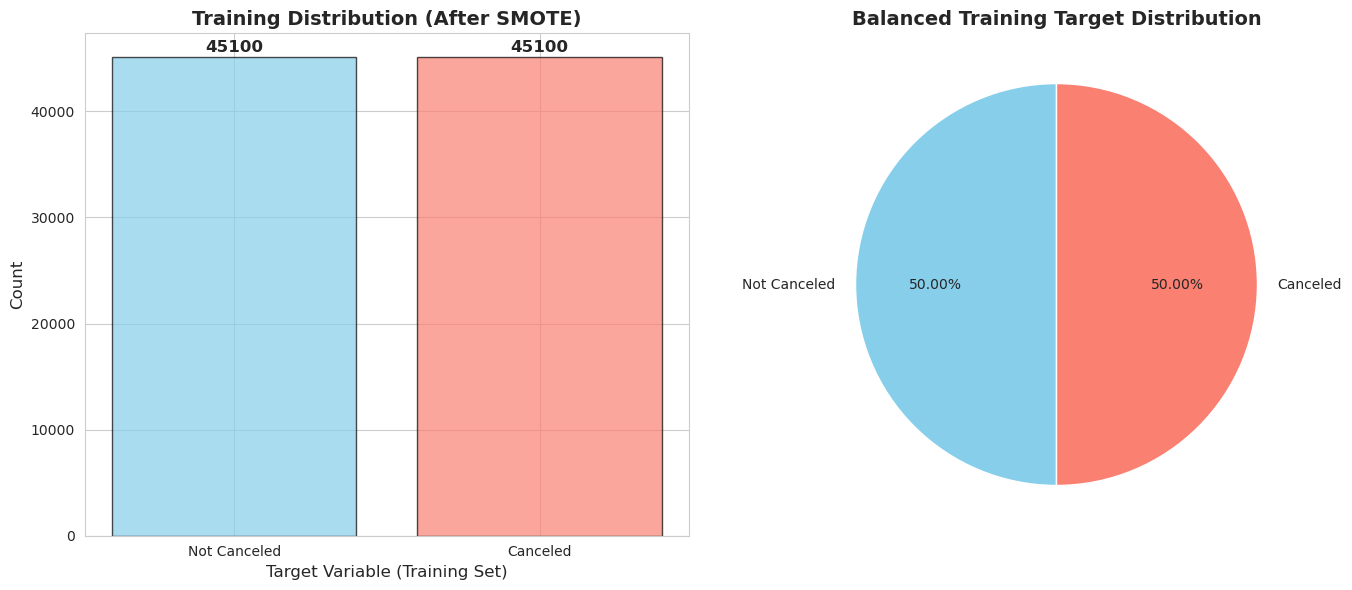


✅ BALANCED TRAINING CLASS DISTRIBUTION:
Not Canceled (0): 45100 (50.00%)
Canceled (1): 45100 (50.00%)
New Training Imbalance Ratio: 1.00:1

NOTE: The Test Set remains original and imbalanced for realistic evaluation.


In [42]:

# Plot target variable distribution
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
target_counts = df['is_canceled'].value_counts()
colors = ['#2ecc71', '#e74c3c']
plt.bar(['Not Canceled', 'Canceled'], target_counts.values, color=colors, alpha=0.7, edgecolor='black')
plt.xlabel('Target Variable', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.title('Target Variable Distribution (Before Balancing)', fontsize=14, fontweight='bold')
for i, v in enumerate(target_counts.values):
    plt.text(i, v + 500, str(v), ha='center', fontsize=12, fontweight='bold')

plt.subplot(1, 2, 2)
plt.pie(target_counts.values, labels=['Not Canceled', 'Canceled'],
        autopct='%1.2f%%', colors=colors, startangle=90)
plt.title('Target Variable Percentage Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nClass Distribution:")
print(f"Not Canceled (0): {target_counts[0]} ({target_counts[0]/len(df)*100:.2f}%)")
print(f"Canceled (1): {target_counts[1]} ({target_counts[1]/len(df)*100:.2f}%)")
print(f"\nImbalance Ratio: {target_counts[0]/target_counts[1]:.2f}:1")

# Check if imbalanced
if target_counts[0] / target_counts[1] > 1.5 or target_counts[1] / target_counts[0] > 1.5:
    print("\n⚠️ DATASET IS IMBALANCED!")
    print("Applying SMOTE (Synthetic Minority Over-sampling Technique) to Training Data...")

    # Apply SMOTE on training data only to avoid data leakage
    smote = SMOTE(random_state=42)
    X_train_final, y_train_final = smote.fit_resample(X_train, y_train)

    # We convert to pd.Series so we can use .value_counts()
    balanced_counts = pd.Series(y_train_final).value_counts()

    # Plotting
    plt.figure(figsize=(14, 6))

    # Bar Chart
    plt.subplot(1, 2, 1)
    # Ensure index 0 and 1 are mapped correctly to labels
    plt.bar(['Not Canceled', 'Canceled'], [balanced_counts[0], balanced_counts[1]], color=['skyblue', 'salmon'], alpha=0.7, edgecolor='black')
    plt.xlabel('Target Variable (Training Set)', fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.title('Training Distribution (After SMOTE)', fontsize=14, fontweight='bold')

    for i, v in enumerate([balanced_counts[0], balanced_counts[1]]):
        plt.text(i, v + 500, str(v), ha='center', fontsize=12, fontweight='bold')

    # Pie Chart
    plt.subplot(1, 2, 2)
    plt.pie([balanced_counts[0], balanced_counts[1]], labels=['Not Canceled', 'Canceled'],
            autopct='%1.2f%%', colors=['skyblue', 'salmon'], startangle=90)
    plt.title('Balanced Training Target Distribution', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

    total_balanced = len(y_train_final)
    print(f"\n✅ BALANCED TRAINING CLASS DISTRIBUTION:")
    print(f"Not Canceled (0): {balanced_counts[0]} ({balanced_counts[0]/total_balanced*100:.2f}%)")
    print(f"Canceled (1): {balanced_counts[1]} ({balanced_counts[1]/total_balanced*100:.2f}%)")
    print(f"New Training Imbalance Ratio: {balanced_counts[0]/balanced_counts[1]:.2f}:1")

    print("\nNOTE: The Test Set remains original and imbalanced for realistic evaluation.")

else:
    print("\nDATASET IS REASONABLY BALANCED!")
    X_train_final, y_train_final = X_train, y_train


In [43]:
# Decision Tree with all features
#Initialize model
dt_all = DecisionTreeClassifier(random_state=42)

# Training
dt_all.fit(X_train_final, y_train_final)

# Validation (It's like a pretend test that shows us results that allow us to tune hyperparameters)
y_pred_dt_val_all = dt_all.predict(X_val)
acc_dt_val_all = accuracy_score(y_val, y_pred_dt_val_all)
f1_dt_val_all = f1_score(y_val, y_pred_dt_val_all)
print(f"--- Decision Tree Baseline Validation ---")
print(f"Validation Accuracy: {acc_dt_val_all:.4f}")
print(f"Validation F1-Score: {f1_dt_val_all:.4f}")

#Testing
y_pred_dt_all = dt_all.predict(X_test)
acc_dt_all = accuracy_score(y_test, y_pred_dt_all)
f1_dt_all = f1_score(y_test, y_pred_dt_all)
print(f"\n--- Decision Tree Baseline Test ---")
print(f"Test Accuracy: {acc_dt_all:.4f}")
print(f"Test F1-Score: {f1_dt_all:.4f}")

--- Decision Tree Baseline Validation ---
Validation Accuracy: 0.8044
Validation F1-Score: 0.7428

--- Decision Tree Baseline Test ---
Test Accuracy: 0.8058
Test F1-Score: 0.7432


In [54]:
### GA 1: using decision trees
dt_model = DecisionTreeClassifier(random_state=42)

ga_dt = GAFeatureSelectionCV(
    estimator=dt_model,
    cv=5,
    scoring="accuracy",
    population_size=50,
    generations=40,
    crossover_probability=0.5,
    mutation_probability=0.2,
    n_jobs=-1,
    verbose=True
)

ga_dt.fit(X_train_final, y_train_final)

selected_features_dt = X.columns[ga_dt.support_]
print("DT Selected Features:", list(selected_features_dt))

# Training
dt_model.fit(X_train_final[selected_features_dt], y_train_final)

# Validation
y_pred_dt_val = dt_model.predict(X_val[selected_features_dt])
print("\n--- Decision tree validation report ---")
print(f"Validation Accuracy: {accuracy_score(y_val, y_pred_dt_val):.4f}")
print(f"Validation F1-Score: {f1_score(y_val, y_pred_dt_val):.4f}")

# Testing
y_pred_dt = dt_model.predict(X_test[selected_features_dt])
acc_dt = accuracy_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
print("DT Accuracy after GA:", acc_dt)
print("--- Decision tree final report ---")
print(classification_report(y_test, y_pred_dt))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

gen	nevals	fitness 	fitness_std	fitness_max	fitness_min
0  	50    	0.754044	0.0390101  	0.813503   	0.635133   
1  	63    	0.783102	0.021366   	0.813503   	0.720942   
2  	75    	0.797946	0.0118345  	0.813503   	0.770333   
3  	69    	0.805774	0.00931774 	0.822483   	0.789047   
4  	68    	0.81254 	0.00580648 	0.826364   	0.793836   
5  	63    	0.81887 	0.00585748 	0.830299   	0.802738   
6  	75    	0.823624	0.00624802 	0.831685   	0.791508   
7  	68    	0.827047	0.00273213 	0.831685   	0.820144   
8  	78    	0.828916	0.00206453 	0.834656   	0.825244   
9  	69    	0.830098	0.00195947 	0.834656   	0.826042   
10 	68    	0.831641	0.00198051 	0.835521   	0.825843   
11 	61    	0.833531	0.00271953 	0.836497   	0.819202   
12 	65    	0.834872	0.00118028 	0.837805   	0.831064   
13 	62    	0.835737	0.00111315 	0.838293   	0.831264   
14 	69    	0.836549	0.000862709	0.838293   	0.834712   
15 	74    	0.837255	0.000834866	0.838703   	0.835754   
16 	77    	0.837706	0.000683307	0.838293   	0.83

In [55]:
# scaling data (necessary for KNN and MLP)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
# we also scale the validation and test splits
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [47]:
# KNN baseline with all features

#Initialize KNN model
knn_all = KNeighborsClassifier(n_neighbors=5, weights='distance')

# Training
knn_all.fit(X_train_scaled, y_train_final)

# Validation
y_pred_knn_val_all = knn_all.predict(X_val_scaled)
acc_knn_val_all = accuracy_score(y_val, y_pred_knn_val_all)
f1_knn_val_all = f1_score(y_val, y_pred_knn_val_all)
print(f"--- KNN Baseline Validation ---")
print(f"Validation Accuracy: {acc_knn_val_all:.4f}")
print(f"Validation F1-Score: {f1_knn_val_all:.4f}")

#Testing
y_pred_knn_all = knn_all.predict(X_test_scaled)
acc_knn_all = accuracy_score(y_test, y_pred_knn_all)
f1_knn_all = f1_score(y_test, y_pred_knn_all)
print(f"\n--- KNN Baseline Test ---")
print(f"Test Accuracy: {acc_knn_all:.4f}")
print(f"Test F1-Score: {f1_knn_all:.4f}")

--- KNN Baseline Validation ---
Validation Accuracy: 0.7795
Validation F1-Score: 0.7019

--- KNN Baseline Test ---
Test Accuracy: 0.7802
Test F1-Score: 0.6990


In [48]:
# GA 2: using KNN
knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance')

ga_knn = GAFeatureSelectionCV(
    estimator=knn_model,
    cv=5,
    scoring="accuracy",
    population_size=30,
    generations=20,
    crossover_probability=0.5,
    mutation_probability=0.2,
    n_jobs=-1,
    verbose=True
)

ga_knn.fit(X_train_scaled, y_train_final)

selected_features_knn = X.columns[ga_knn.support_]  #[:, ga_knn.support_] is a boolean mask that decides which columns to keep (0 for remove, 1 for keep)
print("KNN Selected Features:", list(selected_features_knn))

# Training
knn_model.fit(X_train_scaled[:, ga_knn.support_], y_train_final)

# Validation
y_pred_knn_val = knn_model.predict(X_val_scaled[:, ga_knn.support_])
print("\n--- KNN validation report ---")
print(f"Validation Accuracy: {accuracy_score(y_val, y_pred_knn_val):.4f}")
print(f"Validation F1-Score: {f1_score(y_val, y_pred_knn_val):.4f}")

# Testing
y_pred_knn = knn_model.predict(X_test_scaled[:, ga_knn.support_])
acc_knn = accuracy_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
print("KNN Accuracy after GA:", acc_knn)

print("--- KNN final report ---")
print(classification_report(y_test, y_pred_knn))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))


gen	nevals	fitness 	fitness_std	fitness_max	fitness_min
0  	30    	0.749436	0.0407713  	0.814667   	0.669501   
1  	39    	0.778685	0.0221412  	0.817095   	0.712262   
2  	48    	0.791008	0.0171389  	0.817095   	0.749645   
3  	39    	0.805666	0.00835213 	0.817095   	0.789612   
4  	36    	0.812889	0.00690327 	0.821009   	0.794113   
5  	43    	0.817559	0.00323378 	0.826752   	0.809157   
6  	38    	0.820538	0.00456385 	0.837084   	0.815554   
7  	42    	0.824776	0.0036763  	0.834767   	0.819812   
8  	41    	0.827951	0.00474588 	0.840222   	0.821009   
9  	36    	0.831428	0.00448132 	0.840222   	0.825111   
10 	45    	0.834069	0.00394413 	0.840222   	0.826752   
11 	45    	0.837155	0.00307895 	0.840854   	0.827184   
12 	41    	0.838972	0.00222248 	0.841242   	0.83122    
13 	42    	0.840469	0.00131673 	0.841552   	0.836774   
14 	46    	0.841058	0.000925123	0.84429    	0.838049   
15 	40    	0.841834	0.00129224 	0.844612   	0.840854   
16 	35    	0.842348	0.00422418 	0.845133   	0.82

In [49]:
# MLP baseline with all features

#Initialize model
mlp_all = MLPClassifier(hidden_layer_sizes=(100, 50), solver='adam', max_iter=1000,
                        early_stopping=True, activation='logistic', n_iter_no_change=20, random_state=42)

#Training
mlp_all.fit(X_train_scaled, y_train_final)

# Validation
y_pred_mlp_val_all = mlp_all.predict(X_val_scaled)
acc_mlp_val_all = accuracy_score(y_val, y_pred_mlp_val_all)
f1_mlp_val_all = f1_score(y_val, y_pred_mlp_val_all)
print(f"--- MLP Baseline Validation ---")
print(f"Validation Accuracy: {acc_mlp_val_all:.4f}")
print(f"Validation F1-Score: {f1_mlp_val_all:.4f}")

#Testing
y_pred_mlp_all = mlp_all.predict(X_test_scaled)
acc_mlp_all = accuracy_score(y_test, y_pred_mlp_all)
f1_mlp_all = f1_score(y_test, y_pred_mlp_all)
print(f"\n--- MLP Baseline Test ---")
print(f"Test Accuracy: {acc_mlp_all:.4f}")
print(f"Test F1-Score: {f1_mlp_all:.4f}")

--- MLP Baseline Validation ---
Validation Accuracy: 0.8379
Validation F1-Score: 0.7693

--- MLP Baseline Test ---
Test Accuracy: 0.8406
Test F1-Score: 0.7725


In [50]:
#GA 3: using MLP model

mlp_model = MLPClassifier(hidden_layer_sizes=(100, 50), solver='adam',max_iter=1000, early_stopping=True, activation='logistic', n_iter_no_change=20,random_state=42)


ga_mlp = GAFeatureSelectionCV(
    estimator=mlp_model,
    cv=5,
    scoring="accuracy",
    population_size=30,
    generations=20,
    n_jobs=-1,
    crossover_probability=0.5,
    mutation_probability=0.2,
    verbose=True
)

ga_mlp.fit(X_train_scaled, y_train_final)

selected_features_mlp = X.columns[ga_mlp.support_]
print("MLP Selected Features:", list(selected_features_mlp))

# Training
mlp_model.fit(X_train_scaled[:, ga_mlp.support_], y_train_final)

# Validation
y_pred_mlp_val = mlp_model.predict(X_val_scaled[:, ga_mlp.support_])
print("\n--- MLP validation report ---")
print(f"Validation Accuracy: {accuracy_score(y_val, y_pred_mlp_val):.4f}")
print(f"Validation F1-Score: {f1_score(y_val, y_pred_mlp_val):.4f}")

# Testing
y_pred_mlp = mlp_model.predict(X_test_scaled[:, ga_mlp.support_])
acc_mlp = accuracy_score(y_test, y_pred_mlp)
f1_mlp = f1_score(y_test, y_pred_mlp)
print("MLP Accuracy after GA:", acc_mlp)

print("--- MLP final report ---")
print(classification_report(y_test, y_pred_mlp))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_mlp))


gen	nevals	fitness 	fitness_std	fitness_max	fitness_min
0  	30    	0.764816	0.0314663  	0.814435   	0.690233   
1  	42    	0.792173	0.0218505  	0.834435   	0.73296    
2  	48    	0.814263	0.0108475  	0.843049   	0.798126   
3  	41    	0.826016	0.0101825  	0.843049   	0.800898   
4  	43    	0.835194	0.00615921 	0.843049   	0.819701   
5  	37    	0.838548	0.00358259 	0.843049   	0.834435   
6  	39    	0.841466	0.00337881 	0.851796   	0.834435   
7  	38    	0.843069	0.00277103 	0.851796   	0.834435   
8  	42    	0.844102	0.00232927 	0.851796   	0.841231   
9  	39    	0.846391	0.00284608 	0.851796   	0.842528   
10 	48    	0.847644	0.00155171 	0.851796   	0.844634   
11 	43    	0.848176	0.00104205 	0.850698   	0.844856   
12 	38    	0.848416	0.000549633	0.850698   	0.848226   
13 	38    	0.848527	0.000519121	0.850698   	0.848226   
14 	42    	0.8487  	0.00165136 	0.851741   	0.841851   
15 	38    	0.849614	0.00182318 	0.854135   	0.848226   
16 	41    	0.85045 	0.00217113 	0.854135   	0.84

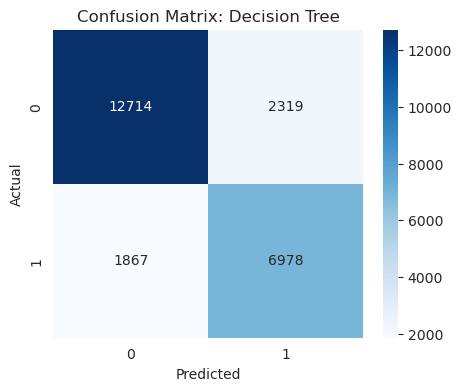

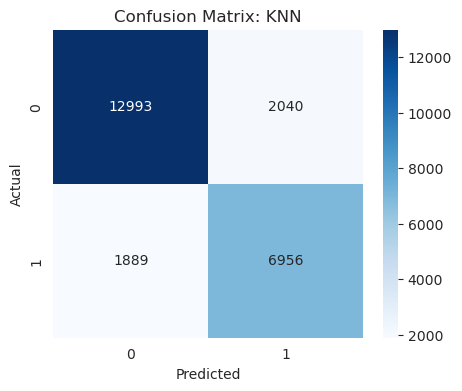

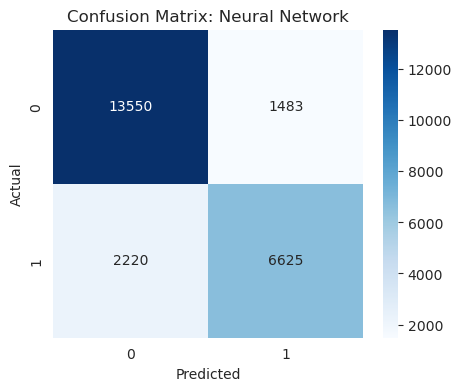

In [58]:
#visualize confusion matrix
def plot_cm(y_test, y_pred, title):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {title}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()


plot_cm(y_test, y_pred_dt, "Decision Tree")
plot_cm(y_test, y_pred_knn, "KNN")
plot_cm(y_test, y_pred_mlp, "Neural Network")

GA Feature Selection Impact Analysis

PERFORMANCE COMPARISON: ALL FEATURES vs GA-SELECTED FEATURES
        Model  All Features - Accuracy  GA Selected - Accuracy  Accuracy Improvement  All Features - F1 Score  GA Selected - F1 Score  F1 Score Improvement  Total Features  GA Selected Features  Feature Reduction %
Decision Tree                 0.805846                0.824692              0.018846                 0.743158                0.769265              0.026107              44                    27            38.636364
          KNN                 0.780216                0.835455              0.055239                 0.699014                0.779777              0.080763              44                    21            52.272727
          MLP                 0.840565                0.844920              0.004355                 0.772513                0.781573              0.009060              44                    33            25.000000


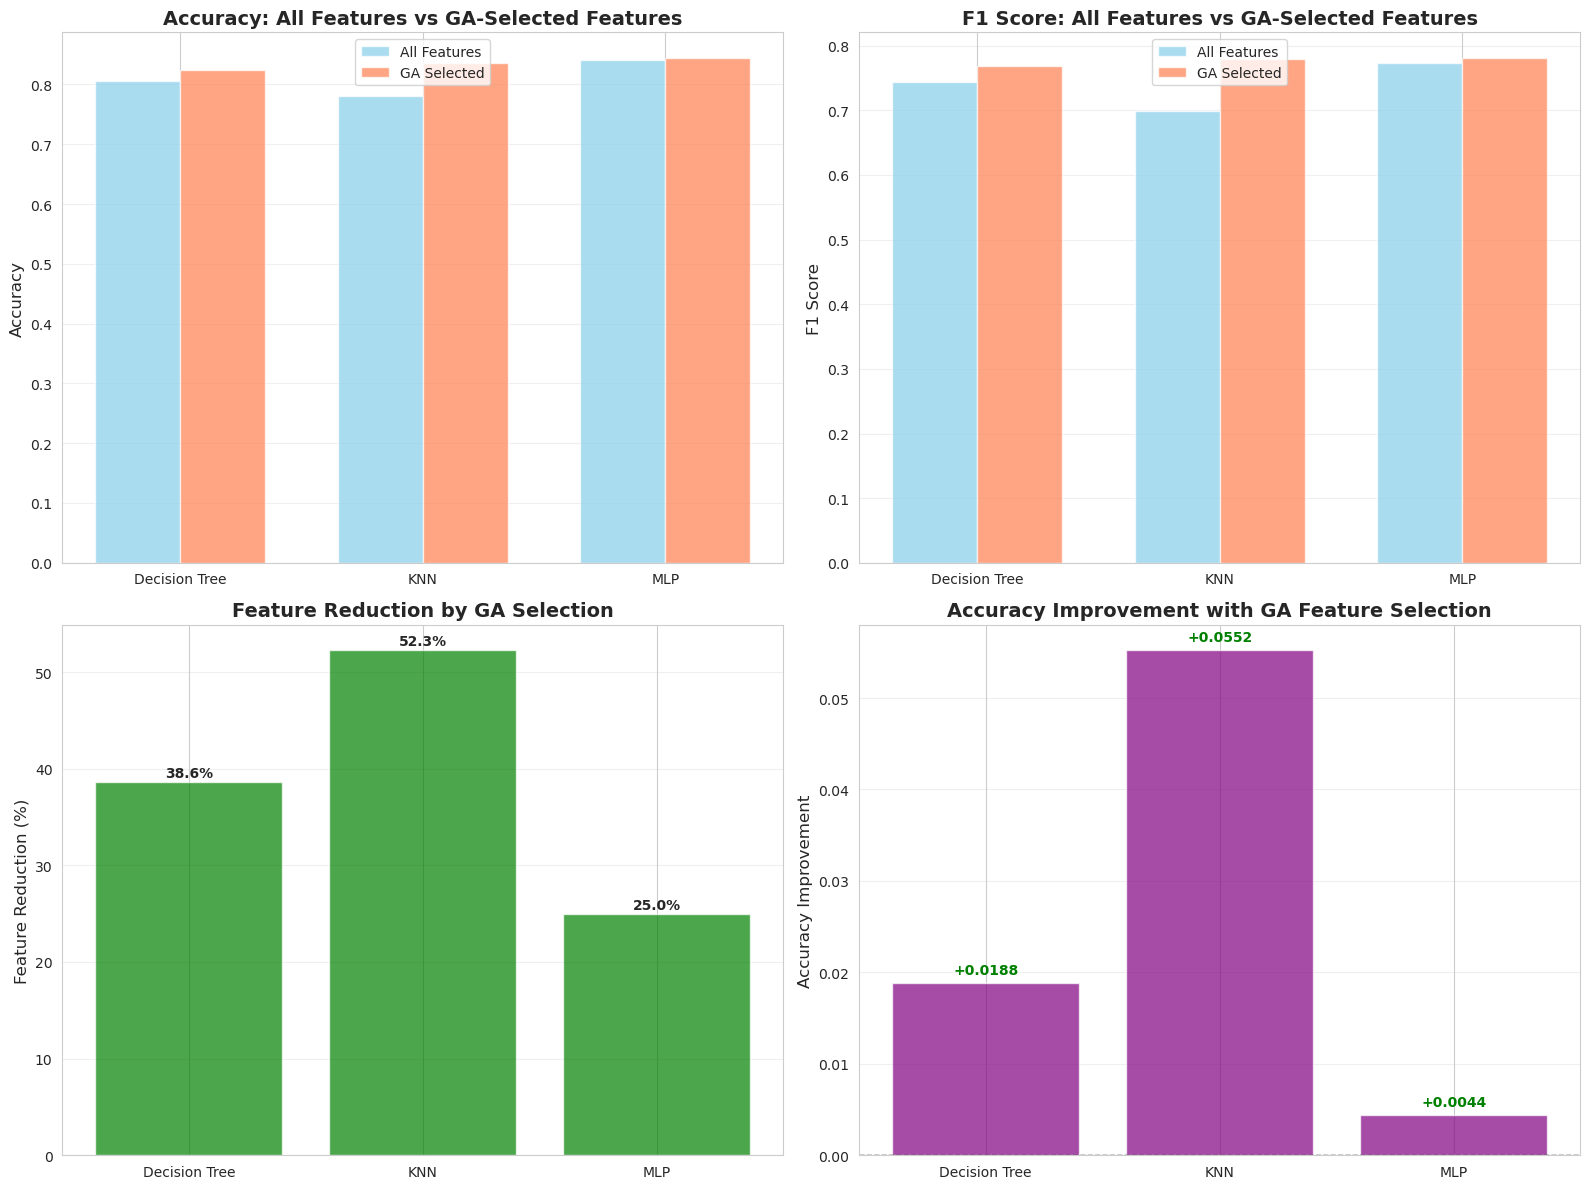


SUMMARY ANALYSIS

Total number of features: 44

Decision Tree:
  - Selected 27 features (38.6% reduction)
  - Accuracy: 0.8058 (all) → 0.8247 (GA) | Change: +0.0188
  - F1 Score: 0.7432 (all) → 0.7693 (GA) | Change: +0.0261

KNN:
  - Selected 21 features (52.3% reduction)
  - Accuracy: 0.7802 (all) → 0.8355 (GA) | Change: +0.0552
  - F1 Score: 0.6990 (all) → 0.7798 (GA) | Change: +0.0808

MLP:
  - Selected 33 features (25.0% reduction)
  - Accuracy: 0.8406 (all) → 0.8449 (GA) | Change: +0.0044
  - F1 Score: 0.7725 (all) → 0.7816 (GA) | Change: +0.0091

CONCLUSION
The Genetic Algorithm successfully selected optimal feature subsets for each model.
This comparison demonstrates the impact of GA feature selection on model performance.


In [59]:
# Testing the Impact of GA Feature Selection on Model Performance comparison
print("="*80)
print("GA Feature Selection Impact Analysis")
print("="*80)

n_features_all = X_train.shape[1]
n_features_dt = len(selected_features_dt)
n_features_knn = len(selected_features_knn)
n_features_mlp = len(selected_features_mlp)

# comparison DataFrame
comparison_data = {
    'Model': ['Decision Tree', 'KNN', 'MLP'],
    'All Features - Accuracy': [acc_dt_all, acc_knn_all, acc_mlp_all],
    'GA Selected - Accuracy': [acc_dt, acc_knn, acc_mlp],
    'Accuracy Improvement': [acc_dt - acc_dt_all, acc_knn - acc_knn_all, acc_mlp - acc_mlp_all],
    'All Features - F1 Score': [f1_dt_all, f1_knn_all, f1_mlp_all],
    'GA Selected - F1 Score': [f1_dt, f1_knn, f1_mlp],
    'F1 Score Improvement': [f1_dt - f1_dt_all, f1_knn - f1_knn_all, f1_mlp - f1_mlp_all],
    'Total Features': [n_features_all] * 3,
    'GA Selected Features': [n_features_dt, n_features_knn, n_features_mlp],
    'Feature Reduction %': [(1 - n_features_dt/n_features_all)*100,
                            (1 - n_features_knn/n_features_all)*100,
                            (1 - n_features_mlp/n_features_all)*100]
}

comparison_df = pd.DataFrame(comparison_data)
print("\n" + "="*80)
print("PERFORMANCE COMPARISON: ALL FEATURES vs GA-SELECTED FEATURES")
print("="*80)
print(comparison_df.to_string(index=False))

# visualize
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
models = comparison_df['Model']
x_pos = range(len(models))

# 1. Accuracy comparison
axes[0, 0].bar(x_pos, comparison_df['All Features - Accuracy'],
               alpha=0.7, label='All Features', color='skyblue', width=0.35)
axes[0, 0].bar([x + 0.35 for x in x_pos], comparison_df['GA Selected - Accuracy'],
               alpha=0.7, label='GA Selected', color='coral', width=0.35)
axes[0, 0].set_ylabel('Accuracy', fontsize=12)
axes[0, 0].set_title('Accuracy: All Features vs GA-Selected Features', fontsize=14, fontweight='bold')
axes[0, 0].set_xticks([x + 0.175 for x in x_pos])
axes[0, 0].set_xticklabels(models)
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3, axis='y')

# 2. F1 comparison
axes[0, 1].bar(x_pos, comparison_df['All Features - F1 Score'],
               alpha=0.7, label='All Features', color='skyblue', width=0.35)
axes[0, 1].bar([x + 0.35 for x in x_pos], comparison_df['GA Selected - F1 Score'],
               alpha=0.7, label='GA Selected', color='coral', width=0.35)
axes[0, 1].set_ylabel('F1 Score', fontsize=12)
axes[0, 1].set_title('F1 Score: All Features vs GA-Selected Features', fontsize=14, fontweight='bold')
axes[0, 1].set_xticks([x + 0.175 for x in x_pos])
axes[0, 1].set_xticklabels(models)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3, axis='y')

# 3. Feature reduction
axes[1, 0].bar(models, comparison_df['Feature Reduction %'], color='green', alpha=0.7)
axes[1, 0].set_ylabel('Feature Reduction (%)', fontsize=12)
axes[1, 0].set_title('Feature Reduction by GA Selection', fontsize=14, fontweight='bold')
axes[1, 0].grid(alpha=0.3, axis='y')
for i, v in enumerate(comparison_df['Feature Reduction %']):
    axes[1, 0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 4. Performance improvement
axes[1, 1].bar(models, comparison_df['Accuracy Improvement'], color='purple', alpha=0.7)
axes[1, 1].set_ylabel('Accuracy Improvement', fontsize=12)
axes[1, 1].set_title('Accuracy Improvement with GA Feature Selection', fontsize=14, fontweight='bold')
axes[1, 1].axhline(y=0, color='black', linestyle='--', linewidth=1)
axes[1, 1].grid(alpha=0.3, axis='y')
for i, v in enumerate(comparison_df['Accuracy Improvement']):
    color = 'green' if v >= 0 else 'red'
    axes[1, 1].text(i, v + (0.001 if v >= 0 else -0.001), f'{v:+.4f}',
                    ha='center', fontweight='bold', color=color)

plt.tight_layout()
plt.show()

# Summary Analysis
print("\n" + "="*80)
print("SUMMARY ANALYSIS")
print("="*80)
print(f"\nTotal number of features: {n_features_all}")

for _, row in comparison_df.iterrows():
    model_name = row['Model']
    print(f"\n{model_name}:")
    print(f"  - Selected {int(row['GA Selected Features'])} features ({row['Feature Reduction %']:.1f}% reduction)")
    print(f"  - Accuracy: {row['All Features - Accuracy']:.4f} (all) → {row['GA Selected - Accuracy']:.4f} (GA) | Change: {row['Accuracy Improvement']:+.4f}")
    print(f"  - F1 Score: {row['All Features - F1 Score']:.4f} (all) → {row['GA Selected - F1 Score']:.4f} (GA) | Change: {row['F1 Score Improvement']:+.4f}")

print("\n" + "="*80)
print("CONCLUSION")
print("="*80)
print("The Genetic Algorithm successfully selected optimal feature subsets for each model.")
print("This comparison demonstrates the impact of GA feature selection on model performance.")
print("="*80)